![Banner](../images/09_09_banner_rs_image_classification.png)


# Transfer Learning and Vision Transformers for Sentinel-2: ImageNet vs Remote-Sensing Weights

Labelled remote-sensing chips are expensive; a model trained from random weights needs thousands of them. **Transfer learning** starts from an encoder that was already trained on a very large image collection and adapts it to the task at hand.


## Overview

This notebook asks four practical questions on a Sentinel-2 scene of the US Corn Belt (Iowa, 26 August 2025, 10 bands at 10 m) with the USDA Cropland Data Layer (CDL) as labels:

1. **How much of the pretrained network should be trained?** A *linear probe* trains only the classification head, *partial* fine-tuning also trains the last stage, *full* fine-tuning trains everything (`set_trainable`, `compare_transfer_modes`).
2. **Which pretraining helps more: ImageNet or remote-sensing weights?** TorchGeo checkpoints from SSL4EO-S12 (self-supervised, Sentinel-2) and Satlas (supervised, Sentinel-2) are loaded with `load_rs_backbone`.
3. **What if the image has more than three bands?** ImageNet filters expect RGB; Sentinel-2 has 10-13 bands (`adapt_input_channels`, band sub-setting of 13-band checkpoints).
4. **How many labelled chips do we need?** A *label-budget curve* shows test accuracy against the number of training chips for every transfer mode.

Along the way the notebook explains the architectures involved (ResNet, Vision Transformer, Swin Transformer) and the pretraining objectives (MoCo, DINO) with their equations, and uses `vit_attention_rollout` to look at **what a Vision Transformer attends to**.


## Core concepts

### Learning objectives

1. Build a spatially isolated, class-balanced chip data set from Sentinel-2 and CDL.
2. Explain the mathematics of residual networks, Vision Transformers, Swin Transformers, and of MoCo / DINO pretraining.
3. Load ImageNet and remote-sensing pretrained backbones and make them accept a 10-band input.
4. Compare linear probe, partial and full fine-tuning with `set_trainable` and `compare_transfer_modes`, with means and standard deviations over seeds.
5. Visualise ViT attention with `vit_attention_rollout` and test it against the labels.
6. Draw and interpret label-budget curves.

### Contents

1. Setup and reproducibility
2. Sentinel-2 imagery and CDL labels
3. A class-balanced chip data set with spatial hold-out
4. The mathematics of transfer learning
5. Model architectures: ResNet, Vision Transformer, Swin Transformer
6. Pretrained weights: ImageNet versus remote sensing
7. More than three bands: adapting the input layer
8. Freezing strategies with `set_trainable`
9. Benchmark: transfer mode × pretraining × architecture
10. What a Vision Transformer looks at: attention rollout
11. Label-budget curves
12. Summary of the experiments
13. AOI-only fine-tuning and prediction beyond the AOI
14. Interpretation, caveats and recommended recipe


### Task

* **Input.** 16 × 16 pixel chips (160 m × 160 m) with 10 Sentinel-2 bands, cut from `Data/08_remote_sensing/08_09_image_classification/Corn_belt/Sentinel_2/2025_08_20250826`.
* **Label.** Majority CDL class of the chip (Corn, Soybeans, Grass/pasture, Developed, Wetland/forest, Other), from `Data/08_remote_sensing/08_09_image_classification/Corn_belt/CDL/10_m/CDL_2025_10m.tif`.
* **Study area.** `Data/08_remote_sensing/08_09_image_classification/Corn_belt/aoi.geojson` (the Sentinel-2 download covers this AOI).
* **Hardware.** A GPU is recommended: the Vision Transformer and Swin experiments take about an hour in total on a laptop GPU.


## Setup and reproducibility

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings, math  # JSON, timing, warnings and maths
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours
import torch, torch.nn as nn, torch.nn.functional as F  # PyTorch, its layers and functions
import timm, torchgeo  # timm and TorchGeo model libraries
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # the data folder, from the notebook folder or the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
S2 = DATA / "Sentinel_2" / "2025_08_20250826"  # the 26 August 2025 Sentinel-2 scene
CDL_PATH = DATA / "CDL" / "10_m" / "CDL_2025_10m.tif"  # the 2025 CDL at 10 m
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon
for p in (S2, CDL_PATH, AOI_PATH):  # every input ...
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
# library versions
print("torch", torch.__version__, "| timm", timm.__version__, "| torchgeo", torchgeo.__version__)
# device
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only: shrink SEEDS / EPOCHS below")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
SEEDS = [0, 1, 2] if DEVICE == "cuda" else [0]      # repeated runs for mean +/- SD
EPOCHS = 6 if DEVICE == "cuda" else 2  # epochs per run (fewer on a CPU)
aoi = json.loads(AOI_PATH.read_text())  # the AOI GeoJSON
print("AOI type:", aoi["type"], "| scene folder:", S2.name)  # its type and the scene folder


torch 2.14.0+cu132 | timm 1.0.30 | torchgeo 0.8.1
device: cuda | NVIDIA RTX A5500 Laptop GPU
AOI type: Feature | scene folder: 2025_08_20250826


## Sentinel-2 imagery and CDL labels

The ten bands blue, green, red, red-edge 1-3, NIR (B8), narrow NIR (B8A) and the two SWIR bands are stacked on the 10 m grid (the 20 m bands are resampled bilinearly). Digital numbers are converted to surface reflectance with `reflectance = DN × 10⁻⁴` (the scene is already offset-corrected). Cloud, shadow and snow pixels from the scene classification layer (SCL) are masked.

The CDL is reprojected to the Sentinel-2 grid with **nearest-neighbour** resampling, since class codes must never be interpolated, and recoded to six classes.


stack (10, 2911, 3032) (band, y, x) | CRS EPSG:32615 | masked (cloud/shadow/nodata) 0.22%


         class  pixel share
          Corn       0.5265
      Soybeans       0.3643
 Grass/pasture       0.0393
     Developed       0.0447
Wetland/forest       0.0141
         Other       0.0112


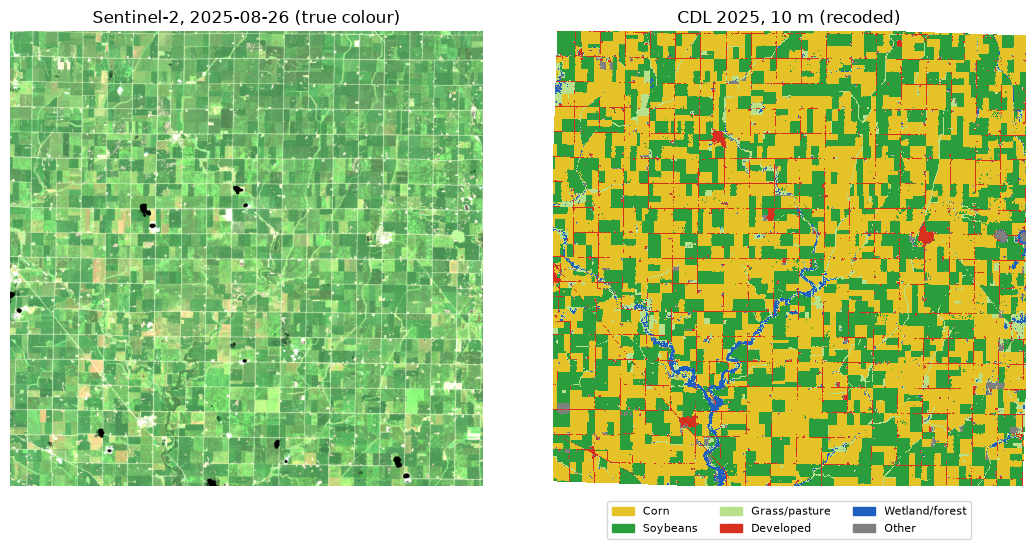

In [2]:
# the ten Sentinel-2 bands
BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
ref = rioxarray.open_rasterio(S2 / "red.tif").squeeze(drop=True)  # the 10 m red band as reference grid
layers = []  # one array per band
for b in BANDS:  # each band
    a = rioxarray.open_rasterio(S2 / f"{b}.tif").squeeze(drop=True)  # read it
    if a.shape != ref.shape:  # a 20 m band ...
        a = a.rio.reproject_match(ref, resampling=1)          # bilinear: 20 m -> 10 m
    layers.append(a.astype("float32"))  # as float32
dn = xr.concat(layers, dim="band").assign_coords(band=BANDS)  # stacked along "band"
# scene classification layer on the 10 m grid
scl = rioxarray.open_rasterio(S2 / "scl.tif").squeeze(drop=True).rio.reproject_match(ref, resampling=0).values
bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11])  # no data, saturated, shadow, cloud, cirrus and snow
bad_da = xr.DataArray(bad, dims=("y", "x"), coords={"y": dn.y, "x": dn.x})  # as a DataArray
refl = (dn.where(dn > 0) * 1e-4).where(~bad_da)  # reflectance with flagged pixels set to missing
refl.name = "reflectance"  # its name
# size, CRS and masked share
print(f"stack {tuple(refl.shape)} (band, y, x) | CRS {refl.rio.crs} | masked (cloud/shadow/nodata) {bad.mean():.2%}")

# CDL on the 10 m grid (nearest neighbour)
cdl = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True).rio.reproject_match(ref, resampling=0)
code_map = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4}  # CDL code -> class id
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # their colour map
raw = cdl.values.astype(int)  # CDL codes as integers
lab = np.full(raw.shape, 5, "int16")  # everything else is "Other" (5)
for k, v in code_map.items():  # the mapped codes ...
    lab[raw == k] = v  # ... get their class
lab[raw == 0] = -1  # no data
share = pd.Series(lab[lab >= 0]).value_counts(normalize=True).sort_index()  # share of each class
# as a small table
print(pd.DataFrame({"class": CLASSES, "pixel share": share.reindex(range(K)).round(4).values}).to_string(index=False))

def rgb(a, lo=0.0, hi=0.07):  # display stretch for an RGB array
    return np.clip((np.nan_to_num(a) - lo) / (hi - lo), 0, 1) ** 0.8  # stretch, clip and brighten slightly

fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))  # two panels
# true colour
ax[0].imshow(rgb(np.moveaxis(refl.sel(band=["red", "green", "blue"]).values, 0, -1))); ax[0].set_title("Sentinel-2, 2025-08-26 (true colour)")
# recoded CDL
ax[1].imshow(np.where(lab < 0, np.nan, lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL 2025, 10 m (recoded)")
for a in ax: a.axis("off")  # no axes
# class legend
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.13))
plt.tight_layout(); plt.show()  # arrange and draw

## A class-balanced chip data set with spatial hold-out

**Chips and labels.** The scene is cut into 16 × 16 pixel chips with a stride of 8 pixels *inside* 256 × 256 pixel blocks (so no chip crosses a block edge). A chip gets the **majority CDL class**; chips with less than 80 % valid labels or with majority share below 50 % are dropped.

**Class balance.** Corn and soybeans cover 90 % of the scene, so a random sample would contain a handful of wetland or "other" chips. We cap every class at 1 200 chips (random draw) so that all six classes are learnable and OA is not dominated by two classes. The consequence is that **all accuracies in this notebook refer to a class-balanced pool, not to the natural class distribution of the scene**.

**Spatial hold-out.** Whole blocks are assigned to train / validation / test with `group_split`, and `check_split_isolation` verifies that no block (and hence no pixel) appears in two sets.


In [3]:
# 16 px chips, 8 px stride, 256 px blocks, at most 1200 chips per class
SIZE, STRIDE, BLOCK, CAP = 16, 8, 256, 1200
nb = min(refl.shape[1], refl.shape[2]) // BLOCK            # 11 x 11 blocks
xs, ys = refl.x.values, refl.y.values  # pixel-centre coordinates
pts, bid = [], []  # chip centres and block ids
for bi in range(nb):  # every block row ...
    for bj in range(nb):  # ... and column
        for r in range(bi * BLOCK, (bi + 1) * BLOCK - SIZE + 1, STRIDE):  # chip rows in the block
            for c in range(bj * BLOCK, (bj + 1) * BLOCK - SIZE + 1, STRIDE):  # chip columns in the block
                # centre and block id of the chip
                pts.append((xs[c + SIZE // 2], ys[r + SIZE // 2])); bid.append(bi * nb + bj)
pts, bid = np.array(pts), np.array(bid)  # as arrays

t0 = time.time()  # start the timer
Xall, _, xy = ic.extract_chips(refl, pts, size=SIZE, max_nan_fraction=0.0)     # drops chips with masked pixels
# candidate centre -> index
cand = {(round(float(a), 3), round(float(b), 3)): i for i, (a, b) in enumerate(pts)}
# index of each kept chip
keep = np.array([cand[(round(float(a), 3), round(float(b), 3))] for a, b in np.asarray(xy)[:, :2]])
lab_da = refl.isel(band=[0]).copy(data=lab[None].astype("float32"))  # the label map as a one-band raster
Mall, _, _ = ic.extract_chips(lab_da, pts, size=SIZE, max_nan_fraction=1.0)  # label chips at the same centres
Mall = Mall[keep, 0].astype(int); bid = bid[keep]                              # (N, 16, 16) label chips
# counts, time and memory
print(f"candidate chips {len(pts):,} -> clean chips {len(Xall):,} ({time.time()-t0:.1f}s) | tensor {Xall.shape}, {Xall.nbytes/1e9:.2f} GB")

valid = Mall >= 0  # labelled pixels of each chip
counts = np.stack([(Mall == k).sum((1, 2)) for k in range(K)], 1)  # pixels of each class per chip
y_all = counts.argmax(1)  # majority class
purity = counts.max(1) / np.maximum(valid.sum((1, 2)), 1)  # its share
ok = (valid.mean((1, 2)) >= 0.8) & (purity >= 0.5)  # chips at least 80 % labelled and 50 % pure
rng = np.random.default_rng(SEED)  # random generator
# at most 1200 chips per class, in their original order
sel = np.sort(np.concatenate([rng.choice(np.flatnonzero(ok & (y_all == k)), min(CAP, int((ok & (y_all == k)).sum())), replace=False) for k in range(K)]))
X, y, groups, M, pur = Xall[sel], y_all[sel], bid[sel], Mall[sel], purity[sel]  # the class-balanced chip pool
# chips available and kept per class
print(pd.DataFrame({"class": CLASSES, "available": np.bincount(y_all[ok], minlength=K), "in pool": np.bincount(y, minlength=K)}).to_string(index=False))
del Xall, Mall  # free the full arrays

candidate chips 116,281 -> clean chips 115,721 (2.2s) | tensor (115721, 10, 16, 16), 1.18 GB
         class  available  in pool
          Corn      62715     1200
      Soybeans      42112     1200
 Grass/pasture       2238     1200
     Developed        852      852
Wetland/forest       1041     1041
         Other        418      418


train 3,821 | val 1,042 | test 1,048 chips (73/24/24 blocks) - isolation check passed
                train  val  test
Corn              743  249   208
Soybeans          726  226   248
Grass/pasture     829  200   171
Developed         596  175    81
Wetland/forest    664   61   316
Other             263  131    24


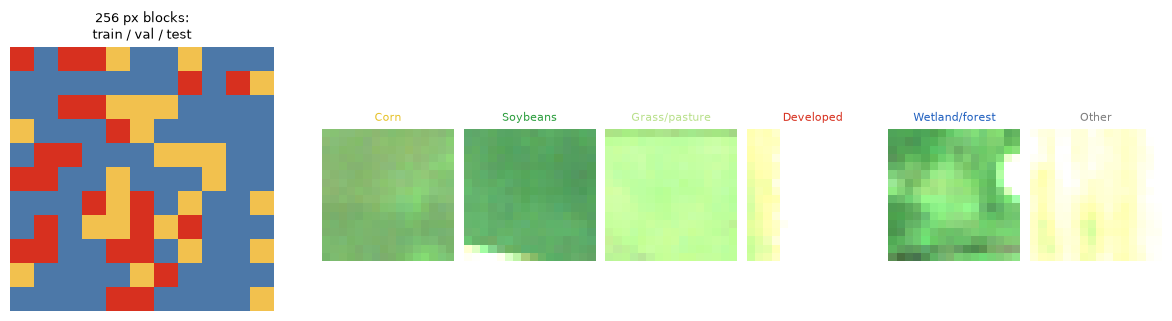

In [4]:
sp = ic.group_split(groups, test_size=0.2, val_size=0.2, seed=SEED)  # 60 / 20 / 20 split by whole blocks
tr, va, te = sp.train, sp.val, sp.test  # the three index sets
# no block in two splits
ic.check_split_isolation(train=np.unique(groups[tr]), val=np.unique(groups[va]), test=np.unique(groups[te]))
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} chips "  # split sizes and block counts
      f"({len(np.unique(groups[tr]))}/{len(np.unique(groups[va]))}/{len(np.unique(groups[te]))} blocks) - isolation check passed")
# chips per class and split
print(pd.DataFrame({s: np.bincount(y[i], minlength=K) for s, i in [("train", tr), ("val", va), ("test", te)]}, index=CLASSES))

fig = plt.figure(figsize=(12, 3.6))  # one figure
# split map axis; split of every block
ax0 = fig.add_axes([0.02, 0.05, 0.22, 0.85]); bsplit = np.full(nb * nb, np.nan)
for v, i in enumerate((tr, va, te)): bsplit[np.unique(groups[i])] = v  # train 0, validation 1, test 2
ax0.imshow(bsplit.reshape(nb, nb), cmap=ListedColormap(["#4c78a8", "#f2c14e", "#d7301f"]), interpolation="nearest")
ax0.set_title("256 px blocks:\ntrain / val / test", fontsize=9); ax0.axis("off")  # title, no axes
for k in range(K):  # each class ...
    a = fig.add_axes([0.28 + k * 0.118, 0.12, 0.11, 0.62])  # its axis
    # a pure example chip of that class
    i = np.flatnonzero((y == k) & (pur > 0.9))[3] if ((y == k) & (pur > 0.9)).sum() > 3 else np.flatnonzero(y == k)[3]
    # shown in true colour
    a.imshow(rgb(np.moveaxis(X[i][[2, 1, 0]], 0, -1)), interpolation="nearest"); a.set_title(CLASSES[k], fontsize=8, color=COLORS[k]); a.axis("off")
plt.show()  # draw

## The mathematics of transfer learning

Write a classifier as an **encoder** $f_\phi:\mathbb R^{C\times H\times W}\to\mathbb R^{D}$ followed by a **head** $h_\psi:\mathbb R^{D}\to\mathbb R^{K}$, so that the class probabilities are $p(\mathbf x)=\operatorname{softmax}\big(h_\psi(f_\phi(\mathbf x))\big)$.

**Pretraining** finds encoder weights $\phi_0$ on a large *source* task (ImageNet labels, a self-supervised objective, or Satlas labels). **Fine-tuning** then solves the *target* problem on $n$ labelled chips,

$$ \min_{\phi,\psi}\;\frac1n\sum_{i=1}^{n}\ell\big(h_\psi(f_\phi(\mathbf x_i)),y_i\big),\qquad \ell=-\log p_{y_i}, $$

with the optimiser started at $(\phi_0,\psi_{\text{random}})$. The three transfer modes differ only in *which parameters are free*:

| mode | free parameters | optimisation problem |
|---|---|---|
| **linear probe** | $\psi$ only, $\phi=\phi_0$ fixed | multinomial logistic regression on fixed features $\mathbf z_i=f_{\phi_0}(\mathbf x_i)$: convex, few parameters ($D\cdot K+K$) |
| **partial** | $\psi$ and the top block(s) $\phi_{\text{top}}$; $\phi_{\text{low}}=\phi_{0,\text{low}}$ | non-convex, low-level filters are reused |
| **full** | $\phi,\psi$ | non-convex, all parameters move; $\phi_0$ is only the starting point |

**Why it works.** Early layers learn generic edge, texture and colour-contrast detectors, later layers learn task-specific combinations. Fixing the early layers shrinks the hypothesis class: the effective number of free parameters $p$ drops from millions to a few thousand, so the variance of the fitted model falls when $n$ is small. With a *small learning rate* full fine-tuning behaves like an implicit penalty $\lambda\lVert\phi-\phi_0\rVert^2$ (the "L2-SP" regulariser): the solution stays close to the pretrained encoder, which is why it usually beats training from scratch for small $n$.

**Why it can fail: domain shift.** A bound of Ben-David et al. relates target and source risk,

$$ \varepsilon_T(h)\;\le\;\varepsilon_S(h)+d_{\mathcal H\Delta\mathcal H}(P_S,P_T)+\lambda^\star, $$

where the divergence term grows when the input distributions differ. ImageNet images are 3-band, centimetre-to-metre resolution photographs; Sentinel-2 chips have 10 bands, 10 m pixels and different statistics. Remote-sensing pretraining attacks exactly this gap, at the cost of a fixed band set and normalisation that we must respect (the *Pretrained weights: ImageNet versus remote sensing* and *More than three bands: adapting the input layer* sections).

**Learning rates.** The head starts from random weights and the encoder from good weights, so the head can take a large step ($10^{-3}$) and the encoder a small one ($10^{-4}$); we use the AdamW optimiser with cosine decay,

$$ \eta_t=\tfrac12\eta_0\big(1+\cos(\pi t/T)\big). $$

**Label efficiency.** For a model with $p$ free parameters the generalisation gap typically scales like $\sqrt{p/n}$. The *label-budget curve* $\text{OA}(n)$ in the *Label-budget curves* section is therefore the right tool to compare transfer modes: they are close for large $n$ and separate when $n$ is small.


## Model architectures: ResNet, Vision Transformer, Swin Transformer

### Residual network (ResNet-18)

A ResNet stacks **residual blocks**. Instead of learning a mapping $H(\mathbf x)$ directly, a block learns the residual $F(\mathbf x)=H(\mathbf x)-\mathbf x$:

$$ \mathbf y=\sigma\big(F(\mathbf x;\{W_1,W_2\})+\mathbf x\big),\qquad F=\mathrm{BN}\big(W_2 * \sigma(\mathrm{BN}(W_1 * \mathbf x))\big), $$

with $3\times3$ convolutions $W_1,W_2$, ReLU $\sigma$, and batch normalisation

$$ \hat x=\frac{x-\mu_{\mathcal B}}{\sqrt{\sigma^2_{\mathcal B}+\epsilon}},\qquad \mathrm{BN}(x)=\gamma\hat x+\beta. $$

The identity shortcut gives the gradient a direct path, $\partial\mathbf y/\partial\mathbf x=I+\partial F/\partial\mathbf x$, which is what makes deep networks trainable. ResNet-18 has a $7\times7$ stride-2 stem, a max-pool, four stages of two basic blocks (64, 128, 256, 512 channels) and a global average pool followed by a linear head, **11.2 M parameters** and a total stride of 32. A $16\times16$ chip would shrink to a single pixel, so we upsample it to $112\times112$ (final map $4\times4$). BatchNorm statistics make a *frozen* ResNet awkward: in linear-probe mode the BN layers still update their running statistics while the module is in training mode.

### Vision Transformer (ViT-S/16)

A ViT cuts the image into non-overlapping $P\times P$ patches and treats them as a **sequence of tokens**. For an image $\mathbf x\in\mathbb R^{H\times W\times C}$ there are $N=HW/P^2$ patches $\mathbf x_p^{(i)}\in\mathbb R^{P^2C}$. They are linearly embedded (this is a $P\times P$ convolution with stride $P$, the only layer that sees the band count $C$), a learnable class token is prepended and position embeddings are added:

$$ \mathbf z_0=\big[\mathbf x_{\text{cls}};\;\mathbf x_p^{(1)}E;\;\dots;\;\mathbf x_p^{(N)}E\big]+E_{\text{pos}},\qquad E\in\mathbb R^{P^2C\times D}. $$

Each of the $L$ transformer layers applies **multi-head self-attention** (MSA) and an MLP, both with pre-normalisation and residual connections:

$$ \mathbf z'_\ell=\mathbf z_{\ell-1}+\mathrm{MSA}\big(\mathrm{LN}(\mathbf z_{\ell-1})\big),\qquad \mathbf z_\ell=\mathbf z'_\ell+\mathrm{MLP}\big(\mathrm{LN}(\mathbf z'_\ell)\big). $$

Inside one attention head, queries, keys and values are linear projections of the tokens, $Q=ZW_Q,\;K=ZW_K,\;V=ZW_V$ with $W\in\mathbb R^{D\times d_k}$, and

$$ A=\operatorname{softmax}\!\Big(\frac{QK^{\top}}{\sqrt{d_k}}\Big)\in\mathbb R^{(N+1)\times(N+1)},\qquad \mathrm{head}=AV,\qquad \mathrm{MSA}(Z)=\big[\mathrm{head}_1;\dots;\mathrm{head}_h\big]W_O. $$

The $\sqrt{d_k}$ keeps the dot products from saturating the softmax. The MLP is $\mathrm{MLP}(\mathbf u)=W_2\,\mathrm{GELU}(W_1\mathbf u)$ with hidden width $4D$. The prediction uses the final class token, $\mathbf s=W_{\text{head}}\,\mathrm{LN}(\mathbf z_L^{0})$.

**ViT-S/16**: $D=384$, $L=12$ layers, $h=6$ heads ($d_k=64$), MLP width 1 536, $P=16$; $22\,$M parameters, about $12D^2$ per layer. At $224\times224$ there are $N=14\times14=196$ tokens. Attention costs $\mathcal O(N^2D)$ per layer, and a ViT has **no built-in locality or translation equivariance**: it must learn from data (or from pretraining) what a CNN gets for free, which is why pretraining matters even more for a ViT. We upsample our $16\times16$ chips to $224\times224$, so that one 16-pixel token covers about one original Sentinel-2 pixel and the $14\times14$ attention map lines up with the chip.

### Swin Transformer (Swin-T and Swin-V2-T)

The Swin Transformer restores a **hierarchy** and **locality**. Tokens start as $4\times4$ patches ($56\times56$ tokens at 224 px, $C=96$ channels). Self-attention is computed only inside non-overlapping $M\times M$ **windows** (W-MSA), with a learned **relative position bias** $B$:

$$ \mathrm{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^{\top}}{\sqrt d}+B\Big)V,\qquad B\in\mathbb R^{M^2\times M^2}, $$

where $B$ is looked up from a table of $(2M-1)^2$ parameters indexed by the relative offset of two tokens. Because windows do not talk to each other, every second block **shifts** the window grid by $\lfloor M/2\rfloor$ pixels (SW-MSA):

$$ \hat{\mathbf z}^{\ell}=\text{W-MSA}(\mathrm{LN}(\mathbf z^{\ell-1}))+\mathbf z^{\ell-1},\quad \mathbf z^{\ell}=\mathrm{MLP}(\mathrm{LN}(\hat{\mathbf z}^{\ell}))+\hat{\mathbf z}^{\ell},\quad \hat{\mathbf z}^{\ell+1}=\text{SW-MSA}(\mathrm{LN}(\mathbf z^{\ell}))+\mathbf z^{\ell},\quad \mathbf z^{\ell+1}=\mathrm{MLP}(\mathrm{LN}(\hat{\mathbf z}^{\ell+1}))+\hat{\mathbf z}^{\ell+1}. $$

Between the four stages, **patch merging** concatenates each $2\times2$ neighbourhood ($4C$ channels) and projects it linearly to $2C$, halving the resolution and doubling the width, exactly like the pooling stages of a CNN ($56^2\to28^2\to14^2\to7^2$ tokens, widths $96\to192\to384\to768$). For $h\times w$ tokens of width $C$ the cost is

$$ \Omega(\text{MSA})=4hwC^2+2(hw)^2C\qquad\text{versus}\qquad \Omega(\text{W-MSA})=4hwC^2+2M^2hwC, $$

i.e. **linear** instead of quadratic in the number of tokens. Swin-T has depths $(2,2,6,2)$, heads $(3,6,12,24)$ and 28 M parameters. **Swin V2**, used by Satlas, replaces the dot product by scaled cosine similarity, $\mathrm{sim}(\mathbf q,\mathbf k)=\cos(\mathbf q,\mathbf k)/\tau+B$, uses a continuous (log-spaced) position bias and post-normalisation, which stabilises large models and changes of resolution.

### Pretraining objectives behind the remote-sensing weights

**SSL4EO-S12** is a *self-supervised* data set of Sentinel-2 (and Sentinel-1) patches from about a quarter of a million locations, four seasons each, and no labels. Two objectives are used, both on two augmented *views* $\mathbf x',\mathbf x''$ of the same patch.

*MoCo* (ResNet weights) pulls the embedding $\mathbf q=g(f(\mathbf x'))$ towards the embedding $\mathbf k^{+}$ of the other view, produced by a **momentum encoder**, and pushes it away from a queue of embeddings $\{\mathbf k^{-}\}$ of other patches (the InfoNCE loss):

$$ \mathcal L_{\text{MoCo}}=-\log\frac{\exp(\mathbf q\!\cdot\!\mathbf k^{+}/\tau)}{\exp(\mathbf q\!\cdot\!\mathbf k^{+}/\tau)+\sum_{\mathbf k^{-}}\exp(\mathbf q\!\cdot\!\mathbf k^{-}/\tau)},\qquad \theta_k\leftarrow m\,\theta_k+(1-m)\,\theta_q. $$

*DINO* (ViT weights) has no negatives. A student network is trained to match the output distribution of a teacher that is an exponential moving average of the student:

$$ \mathcal L_{\text{DINO}}=-\sum_{k}P_t^{(k)}(\mathbf x')\,\log P_s^{(k)}(\mathbf x''),\qquad P^{(k)}(\mathbf x)=\frac{\exp(g_k(\mathbf x)/\tau)}{\sum_{j}\exp(g_j(\mathbf x)/\tau)}, $$

with a sharpened teacher (low $\tau_t$) and a centring term to avoid collapse. DINO features of a ViT are known to carry object-like attention maps, which motivates the *What a Vision Transformer looks at: attention rollout* section.

**Satlas** weights (Swin-V2) are *supervised*: the network is trained on a large, multi-task collection of labelled Sentinel-2, Landsat, Sentinel-1 and NAIP tiles. Because the labels are semantic (land cover, buildings, crops, ...) the features are closer to a crop-type task than those of a purely self-supervised model, but the checkpoint expects a very specific input convention (see *Pretrained weights: ImageNet versus remote sensing*).


In [5]:
# the 13 Sentinel-2 bands of SSL4EO-S12
S2_13 = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B10", "B11", "B12"]
OUR_B = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]      # Sentinel-2 names of our 10 channels (BANDS order)
SATLAS_ORDER = ["B4", "B3", "B2", "B5", "B6", "B7", "B8", "B11", "B12"]      # input order of the Satlas multispectral checkpoint
SAT_IDX = [OUR_B.index(b) for b in SATLAS_ORDER]  # positions of the Satlas bands in our stack
SSL_KEEP = [S2_13.index(b) for b in OUR_B]                                   # our bands inside the 13 SSL4EO channels
print("SSL4EO input channels we do not have:", [b for b in S2_13 if b not in OUR_B])  # the SSL4EO bands we lack

def keep_input_bands(model, keep):  # cut a pretrained stem down to the bands we have
    '''Slice the pretrained stem filters to the bands we have (13 -> 10) instead of feeding zeros.'''
    for name, m in model.named_modules():  # every module ...
        if isinstance(m, nn.Conv2d):  # the first convolution
            # a new convolution for fewer input bands
            new = nn.Conv2d(len(keep), m.out_channels, m.kernel_size, m.stride, m.padding, m.dilation, m.groups, m.bias is not None)
            with torch.no_grad():  # no gradients needed
                new.weight.copy_(m.weight[:, keep])  # copy the filters of the kept bands
                if m.bias is not None:  # bias present
                    new.bias.copy_(m.bias)  # copy it
            ic._replace_module(model, name, new)  # swap the layer in
            return model  # done after the first convolution

def resize_input(model, size):  # upsample chips to the pretraining size inside the model
    '''Bilinear up-sampling of the chip to the pretraining resolution (a forward pre-hook keeps the module structure intact).'''
    # resize the input before every forward pass
    model.register_forward_pre_hook(lambda m, a: (F.interpolate(a[0], size=(size, size), mode="bilinear", align_corners=False),))
    return model  # the same model

def satlas_input(Xr):  # Satlas input scaling
    '''Satlas Sentinel-2 convention: RGB as 8-bit TCI (reflectance / 0.3 clipped, x255) divided by 255, other bands DN / 8160.'''
    Z = Xr[:, SAT_IDX].copy()  # Satlas band order
    Z[:, :3] = np.clip(Z[:, :3] / 0.3, 0, 1)  # RGB: reflectance / 0.3, clipped
    Z[:, 3:] = Z[:, 3:] * 1e4 / 8160  # other bands: DN / 8160
    return Z.astype("float32")  # as float32

norm = ic.Normalizer("zscore").fit(X[tr], band_axis=1)                     # training chips only
DATASETS = {"std": lambda idx: ic.ChipDataset(X[idx], y[idx], normalizer=norm),      # z-scored bands (ImageNet and scratch)
            "refl": lambda idx: ic.ChipDataset(X[idx], y[idx]),                      # raw reflectance (SSL4EO convention, DN / 10000)
            "satlas": lambda idx: ic.ChipDataset(satlas_input(X[idx]), y[idx])}      # Satlas convention

ARCH = {  # name: (label, family, weights, input recipe, upsampled size)
    "r18_scratch":   ("ResNet-18 / scratch",        "ResNet-18", "scratch",          "std",    112),
    "r18_imagenet":  ("ResNet-18 / ImageNet",       "ResNet-18", "ImageNet",         "std",    112),
    "r18_ssl4eo":    ("ResNet-18 / SSL4EO MoCo",    "ResNet-18", "SSL4EO-S12 MoCo",  "refl",   112),
    "vits_scratch":  ("ViT-S/16 / scratch",         "ViT-S/16",  "scratch",          "std",    224),
    "vits_imagenet": ("ViT-S/16 / ImageNet",        "ViT-S/16",  "ImageNet",         "std",    224),
    "vits_ssl4eo":   ("ViT-S/16 / SSL4EO DINO",     "ViT-S/16",  "SSL4EO-S12 DINO",  "refl",   224),
    "swint_scratch": ("Swin-T / scratch",           "Swin-T",    "scratch",          "std",    224),
    "swint_imagenet":("Swin-T / ImageNet",          "Swin-T",    "ImageNet",         "std",    224),
    "swint_satlas":  ("Swin-V2-T / Satlas",         "Swin-T",    "Satlas",           "satlas", 224),
}

def make(name, first_conv="mean"):  # build one of the nine models
    size = ARCH[name][4]  # its input size
    # ResNet-18 from scratch
    if name == "r18_scratch":    m = ic.build_cnn("resnet18", in_channels=10, num_classes=K)
    # ResNet-18 with ImageNet weights, stem adapted to 10 bands
    elif name == "r18_imagenet": m = ic.build_cnn("resnet18", in_channels=10, num_classes=K, pretrained=True, first_conv=first_conv)
    # ResNet-18 with SSL4EO MoCo weights, stem cut to our bands
    elif name == "r18_ssl4eo":   m = keep_input_bands(ic.load_rs_backbone("ssl4eo_s2_resnet18_moco", num_classes=K), SSL_KEEP)
    # ViT-S/16 from scratch
    elif name == "vits_scratch": m = ic.build_cnn("timm:vit_small_patch16_224", in_channels=10, num_classes=K)
    # ViT-S/16 with ImageNet weights
    elif name == "vits_imagenet":m = ic.build_cnn("timm:vit_small_patch16_224", in_channels=10, num_classes=K, pretrained=True)
    # ViT-S/16 with SSL4EO DINO weights
    elif name == "vits_ssl4eo":  m = keep_input_bands(ic.load_rs_backbone("ssl4eo_s2_vits16_dino", num_classes=K), SSL_KEEP)
    # Swin-T from scratch
    elif name == "swint_scratch":m = ic.build_cnn("swin_t", in_channels=10, num_classes=K)
    # Swin-T with ImageNet weights
    elif name == "swint_imagenet":m = ic.build_cnn("swin_t", in_channels=10, num_classes=K, pretrained=True, first_conv=first_conv)
    # Swin-V2-T with Satlas weights
    elif name == "swint_satlas": m = ic.load_rs_backbone("satlas_s2_swint_ms", num_classes=K)
    return resize_input(m, size)  # with the input resizing

rows = []  # one row per model
for n_ in ARCH:  # each model
    m = make(n_)  # build it
    # size and input channels
    rows.append(dict(model=ARCH[n_][0], parameters_M=round(ic.count_parameters(m, False) / 1e6, 2), input_channels=next(p for p in m.parameters() if p.ndim == 4).shape[1], upsampled_to=ARCH[n_][4], input_recipe=ARCH[n_][3]))
arch_tab = pd.DataFrame(rows)  # as a table
print(arch_tab.to_string(index=False))  # show it

SSL4EO input channels we do not have: ['B1', 'B9', 'B10']


                  model  parameters_M  input_channels  upsampled_to input_recipe
    ResNet-18 / scratch         11.20              10           112          std
   ResNet-18 / ImageNet         11.20              10           112          std
ResNet-18 / SSL4EO MoCo         11.20              10           112         refl
     ViT-S/16 / scratch         22.36              10           224          std
    ViT-S/16 / ImageNet         22.36              10           224          std
 ViT-S/16 / SSL4EO DINO         22.36              10           224         refl
       Swin-T / scratch         27.53              10           224          std
      Swin-T / ImageNet         27.53              10           224          std
     Swin-V2-T / Satlas         27.60               9           224       satlas


The table shows the nine models used below. Models with the same family have the same architecture and differ only in the **initial weights** (random, ImageNet, remote sensing) and, with them, in the **input convention**:

* `std`: every band is z-scored with the mean and standard deviation of the training chips (ImageNet and scratch models).
* `refl`: surface reflectance as it is (`DN / 10 000`), which is the convention of the SSL4EO checkpoints in TorchGeo (`Normalize(mean=0, std=10000)` on the digital numbers).
* `satlas`: the Satlas Sentinel-2 convention (see *Pretrained weights: ImageNet versus remote sensing*).


## Pretrained weights: ImageNet versus remote sensing

`load_rs_backbone(name)` returns a backbone with remote-sensing weights from TorchGeo; `RS_WEIGHTS` lists the available checkpoints. The input band set, band order and normalisation are part of the checkpoint, so they are stored in `model.rs_weights_meta` and must be checked before use (as must the licence of each checkpoint).


In [6]:
# the remote-sensing weights GeoLattice knows
rs = pd.DataFrame([(k, a, e.split(".")[0], e.split(".")[1]) for k, (a, e) in ic.RS_WEIGHTS.items()], columns=["name", "architecture", "weights class", "checkpoint"])
print(rs.to_string(index=False))  # show them
print()  # blank line
for n_ in ("ssl4eo_s2_resnet18_moco", "ssl4eo_s2_vits16_dino", "satlas_s2_swint_ms"):  # three of them
    meta = ic.load_rs_backbone(n_, num_classes=K).rs_weights_meta  # their metadata
    # dataset and input bands
    print(f"{n_:26s} data: {meta.get('dataset')} | input bands ({meta.get('in_chans')}): {', '.join(meta['bands'])}")

                       name          architecture      weights class              checkpoint
    ssl4eo_s2_resnet18_moco              resnet18   ResNet18_Weights      SENTINEL2_ALL_MOCO
    ssl4eo_s2_resnet50_moco              resnet50   ResNet50_Weights      SENTINEL2_ALL_MOCO
    ssl4eo_s2_resnet50_dino              resnet50   ResNet50_Weights      SENTINEL2_ALL_DINO
ssl4eo_s2_rgb_resnet50_moco              resnet50   ResNet50_Weights      SENTINEL2_RGB_MOCO
    ssl4eo_s1_resnet50_moco              resnet50   ResNet50_Weights      SENTINEL1_ALL_MOCO
      ssl4eo_s2_vits16_dino vit_small_patch16_224 ViTSmall16_Weights      SENTINEL2_ALL_DINO
    ssl4eo_l8_resnet50_moco              resnet50   ResNet50_Weights     LANDSAT_OLI_SR_MOCO
        satlas_s2_swinb_rgb             swin_v2_b  Swin_V2_B_Weights SENTINEL2_SI_RGB_SATLAS
         satlas_s2_swinb_ms             swin_v2_b  Swin_V2_B_Weights  SENTINEL2_SI_MS_SATLAS
        satlas_s2_swint_rgb             swin_v2_t  Swin_V2_T_Weights S

ssl4eo_s2_vits16_dino      data: SSL4EO-S12 | input bands (13): B1, B2, B3, B4, B5, B6, B7, B8, B8a, B9, B10, B11, B12


satlas_s2_swint_ms         data: SatlasPretrain | input bands (9): B04, B03, B02, B05, B06, B07, B08, B11, B12


**Our input recipes.**

| checkpoint | expects | what we do |
|---|---|---|
| SSL4EO-S12 (ResNet-18 MoCo, ViT-S/16 DINO) | 13 Sentinel-2 bands B1-B12, reflectance $\times 10^4$ divided by $10^4$ | we have no B1 (coastal aerosol), B9 (water vapour) or B10 (cirrus); the stem filters of these three channels are **removed** (`keep_input_bands`), the remaining ten keep their pretrained weights |
| Satlas Swin-V2-T (`satlas_s2_swint_ms`) | 9 bands in the order B4, B3, B2, B5, B6, B7, B8, B11, B12; RGB as 8-bit TCI $/255$, others $/8160$ | reorder and rescale with `satlas_input` |
| ImageNet (torchvision / timm) | RGB, ImageNet statistics | stem adapted to 10 bands (see *More than three bands: adapting the input layer*), bands z-scored |

The Satlas RGB convention (reflectance divided by 0.3, clipped, i.e. the 8-bit true-colour product) is our reading of the TorchGeo normalisation constants (`std = 255` for RGB, `8160` for the others); other pipelines may differ slightly.


## More than three bands: adapting the input layer

A pretrained RGB stem has weights $W\in\mathbb R^{O\times3\times k\times k}$. For a $C$-band input `adapt_input_channels` builds $W'\in\mathbb R^{O\times C\times k\times k}$ and rescales by $3/C$ so that the *expected activation magnitude* stays the same as for the RGB input:

$$ \textbf{mean:}\;\;W'_{:,c}=\tfrac{3}{C}\,\bar W\ (c>3),\quad W'_{:,c}=\tfrac{3}{C}W_{:,c}\ (c\le3),\;\;\bar W=\tfrac13\sum_{j=1}^{3}W_{:,j};\qquad \textbf{repeat:}\;\;W'_{:,c}=\tfrac{3}{C}\,W_{:,\,c \bmod 3}; $$

$$ \textbf{random:}\;\;W'\sim\text{Kaiming normal (stem trained from scratch).} $$

Bands such as the red edge or SWIR start with a copy of an RGB filter, which is a poor but harmless initialisation: the fine-tuning step re-learns it. For a 13-band remote-sensing checkpoint nothing needs to be invented: we **subset** the filters instead. The next cell shows both routes.


RGB stem: (64, 3, 7, 7)


method           stem  weight_std  activation_std
  mean (64, 10, 7, 7)      0.0349          1.2338
repeat (64, 10, 7, 7)      0.0389          1.4370
random (64, 10, 7, 7)      0.0251          0.5526

SSL4EO stem 13 -> 10 bands: (64, 13, 7, 7) -> (64, 10, 7, 7) | filters identical to the pretrained ones: True


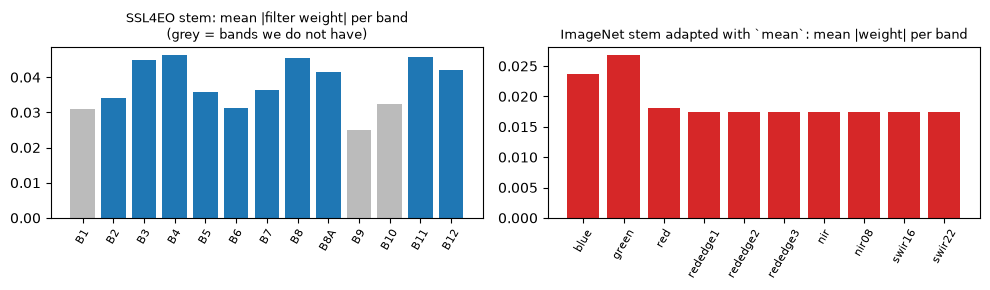

In [7]:
# ResNet-18 with ImageNet weights and an RGB stem
base = ic.build_cnn("resnet18", in_channels=3, num_classes=K, pretrained=True)
print("RGB stem:", tuple(base.conv1.weight.shape))  # stem shape
xb = torch.from_numpy(norm.transform(X[tr[:256]], band_axis=1)).float()  # 256 normalised training chips
rows = []  # one row per method
for method in ("mean", "repeat", "random"):  # three ways to widen the stem to 10 bands
    # adapt the stem
    m = ic.adapt_input_channels(ic.build_cnn("resnet18", in_channels=3, num_classes=K, pretrained=True), 10, method=method)
    with torch.no_grad():  # no gradients needed
        z = m.conv1(xb)  # stem output on the chips
    # filter and activation spread
    rows.append(dict(method=method, stem=tuple(m.conv1.weight.shape), weight_std=float(m.conv1.weight.std()), activation_std=float(z.std())))
print(pd.DataFrame(rows).round(4).to_string(index=False))  # compare them

ssl = ic.load_rs_backbone("ssl4eo_s2_resnet18_moco", num_classes=K)  # the SSL4EO ResNet-18
w13 = ssl.conv1.weight.detach().clone()  # its 13-band stem
# the stem cut to our 10 bands
sub = keep_input_bands(ic.load_rs_backbone("ssl4eo_s2_resnet18_moco", num_classes=K), SSL_KEEP)
# shapes, and the kept filters are unchanged
print("\nSSL4EO stem 13 -> 10 bands:", tuple(w13.shape), "->", tuple(sub.conv1.weight.shape),
      "| filters identical to the pretrained ones:", bool(torch.equal(sub.conv1.weight.detach(), w13[:, SSL_KEEP])))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))  # two panels
ax[0].bar(range(13), w13.abs().mean((0, 2, 3)).numpy(), color=["#bbb" if b not in OUR_B else "#1f77b4" for b in S2_13]); ax[0].set_xticks(range(13)); ax[0].set_xticklabels(S2_13, rotation=60, fontsize=8)
# title
ax[0].set_title("SSL4EO stem: mean |filter weight| per band\n(grey = bands we do not have)", fontsize=9)
ax[1].bar(range(10), ic.adapt_input_channels(ic.build_cnn("resnet18", in_channels=3, num_classes=K, pretrained=True), 10).conv1.weight.abs().mean((0, 2, 3)).detach().numpy(), color="#d62728")
# band names and title
ax[1].set_xticks(range(10)); ax[1].set_xticklabels(BANDS, rotation=60, fontsize=8); ax[1].set_title("ImageNet stem adapted with `mean`: mean |weight| per band", fontsize=9)
plt.tight_layout(); plt.show()  # arrange and draw

### Does the stem initialisation matter?

The same ResNet-18 with ImageNet weights is fine-tuned (all layers) with each stem-adaptation method; ten-band input, three seeds. Training and evaluation helpers are defined here and reused in the rest of the notebook.


In [8]:
LR = {"linear_probe": 1e-3, "partial": 3e-4, "full": 1e-4}      # head learns fast, pretrained encoder slowly
LR_SCRATCH = 3e-4  # learning rate when training from scratch
KEEP = {}                                                       # trained models kept for the attention analysis

# train one model and score it on the test chips
def run(name, mode, seed, idx=None, epochs=EPOCHS, val=True, bs=64, first_conv="mean", keep=False):
    ic.set_seed(seed)  # same initial weights for a given seed
    m = make(name, first_conv=first_conv)  # build the model
    cnt = ic.set_trainable(m, mode)  # freeze according to the transfer mode
    dk = ARCH[name][3]  # its input recipe
    idx = tr if idx is None else idx  # the training chips (all unless idx is given)
    # shuffled training batches
    ltr = ic.as_loader(DATASETS[dk](idx), bs, shuffle=True, seed=seed, drop_last=True)
    lva = ic.as_loader(DATASETS[dk](va), 256, shuffle=False) if val else None  # validation batches
    lte = ic.as_loader(DATASETS[dk](te), 256, shuffle=False)  # test batches
    lr = LR_SCRATCH if "scratch" in name else LR[mode]  # learning rate for this model and mode
    t0 = time.time()  # start the timer
    # the GeoLattice training loop
    h = ic.train_model(m, ltr, lva, epochs=epochs, lr=lr, precision="16" if DEVICE == "cuda" else "32", verbose=False, seed=seed, device=DEVICE)
    pred = ic.predict_proba_batches(m, lte, batch_size=256, device=DEVICE).argmax(1)  # test predictions
    rep = ic.classification_report(y[te], pred)  # test report
    if keep:  # keep the model ...
        KEEP[(name, mode)] = m  # ... for later analysis
    # one result row and the model
    return dict(model=name, weights=ARCH[name][2], family=ARCH[name][1], mode=mode, seed=seed, n_train=len(idx), trainable=cnt["trainable"],
                val_acc=max(h["val_score"]) if h["val_score"] else np.nan, test_oa=rep["overall_accuracy"], test_f1=rep["macro_f1"], sec=time.time() - t0), rep

rows = []  # one row per run
for fc in ("mean", "repeat", "random"):  # three ways to adapt the ImageNet stem
    for s in SEEDS:  # each seed
        # train with full fine-tuning
        r, _ = run("r18_imagenet", "full", s, first_conv=fc); r["first_conv"] = fc; rows.append(r)
# mean and spread per stem method
stem_tab = pd.DataFrame(rows).groupby("first_conv", sort=False).agg(val_acc=("val_acc", "mean"), test_oa=("test_oa", "mean"), test_oa_sd=("test_oa", "std"), test_f1=("test_f1", "mean"), sec=("sec", "mean"))
print(stem_tab.round(4))  # show it

            val_acc  test_oa  test_oa_sd  test_f1     sec
first_conv                                               
mean         0.8410   0.9227      0.0069   0.8568  7.1766
repeat       0.8417   0.9036      0.0141   0.8358  7.0746
random       0.8573   0.9084      0.0095   0.8502  7.1204


## Freezing strategies with `set_trainable`

`set_trainable(model, mode, n_blocks=1)` sets `requires_grad` and returns the number of trainable and total parameters.

* `linear_probe`: only the head (`fc` / `head`) trains.
* `partial`: the head, the last `n_blocks` stages (`layer4` of a ResNet, the last transformer block of a ViT, the last stage of a Swin) and the final normalisation layer train.
* `full`: everything trains.

`compare_transfer_modes(build_fn, train_loader, val_loader, modes=, epochs=, lr=)` runs the three modes on fresh copies of the same pretrained model and tabulates trainable parameters, data volume and best validation accuracy.


In [9]:
rows = []  # one row per model and mode
# the six pretrained models
for n_ in ("r18_imagenet", "r18_ssl4eo", "vits_imagenet", "vits_ssl4eo", "swint_imagenet", "swint_satlas"):
    for mode in ("linear_probe", "partial", "full"):  # the three transfer modes
        c = ic.set_trainable(make(n_), mode)  # trainable parameters in this mode
        # counts and share
        rows.append(dict(model=ARCH[n_][0], mode=mode, trainable=c["trainable"], total=c["total"], share=c["trainable"] / c["total"]))
cnt_tab = pd.DataFrame(rows)  # as a table
# trainable parameters
print(cnt_tab.pivot(index="model", columns="mode", values="trainable")[["linear_probe", "partial", "full"]].to_string())
print()  # blank line
# as percentages
print((cnt_tab.pivot(index="model", columns="mode", values="share")[["linear_probe", "partial", "full"]] * 100).round(2).astype(str).add(" %").to_string())

dk = "refl"  # SSL4EO convention: raw reflectance
ltr0 = ic.as_loader(DATASETS[dk](tr), 64, shuffle=True, seed=0, drop_last=True)  # training batches
lva0 = ic.as_loader(DATASETS[dk](va), 256, shuffle=False)  # validation batches
t0 = time.time()  # start the timer
# the three modes trained and compared by GeoLattice
cmp_tab = ic.compare_transfer_modes(lambda: make("r18_ssl4eo"), ltr0, lva0, epochs=EPOCHS, lr=LR, region="Corn Belt, Iowa",
                                    precision="16" if DEVICE == "cuda" else "32", device=DEVICE, seed=0)
print(f"\ncompare_transfer_modes (ResNet-18 / SSL4EO, {time.time()-t0:.0f} s):")  # time
print(cmp_tab.round(4).to_string(index=False))  # the comparison

mode                     linear_probe   partial      full
model                                                    
ResNet-18 / ImageNet             3078   8396806  11201542
ResNet-18 / SSL4EO MoCo          3078   8396806  11201542
Swin-T / ImageNet                4614  14190006  27534720
Swin-V2-T / Satlas               4614  14209590  27596400
ViT-S/16 / ImageNet              2310   1777542  22356102
ViT-S/16 / SSL4EO DINO           2310   1777542  22356102

mode                    linear_probe  partial     full
model                                                 
ResNet-18 / ImageNet          0.03 %  74.96 %  100.0 %
ResNet-18 / SSL4EO MoCo       0.03 %  74.96 %  100.0 %
Swin-T / ImageNet             0.02 %  51.53 %  100.0 %
Swin-V2-T / Satlas            0.02 %  51.49 %  100.0 %
ViT-S/16 / ImageNet           0.01 %   7.95 %  100.0 %
ViT-S/16 / SSL4EO DINO        0.01 %   7.95 %  100.0 %



compare_transfer_modes (ResNet-18 / SSL4EO, 14 s):
        mode  trainable    total  n_train          region  best_val_score  best_val_loss
linear_probe       3078 11201542     3821 Corn Belt, Iowa          0.7601         1.1299
     partial    8396806 11201542     3821 Corn Belt, Iowa          0.8464         0.5687
        full   11201542 11201542     3821 Corn Belt, Iowa          0.8647         0.5272


## Benchmark: transfer mode × pretraining × architecture

Every combination of architecture family (ResNet-18, ViT-S/16, Swin-T), pretraining (random, ImageNet, remote sensing) and transfer mode (linear probe, partial, full) is trained on the full training set and evaluated on the **held-out test blocks**. Learning rates and epochs are fixed in advance (see *More than three bands: adapting the input layer*) and are the same for all weights of a family. Results are means ± SD over seeds (the seed changes the random head, batch order and, for scratch models, the encoder). Swin models use two seeds to keep the run time reasonable.


In [10]:
bench_rows = []  # one row per run
t00 = time.time()  # start the timer
# every model
for n_ in ("r18_scratch", "r18_imagenet", "r18_ssl4eo", "vits_scratch", "vits_imagenet", "vits_ssl4eo", "swint_scratch", "swint_imagenet", "swint_satlas"):
    # three modes for pretrained models, full training from scratch
    modes = ["full"] if "scratch" in n_ else ["linear_probe", "partial", "full"]
    seeds = SEEDS[:2] if n_.startswith("swint") else SEEDS  # fewer seeds for Swin (slow)
    for mode in modes:  # each mode
        for s in seeds:  # each seed
            # train; keep the seed-0 ViT models for attention maps
            r, _ = run(n_, mode, s, keep=(s == 0 and n_.startswith("vits") and mode == "full"))
            bench_rows.append(r)  # collect the row
        d = pd.DataFrame(bench_rows).query("model == @n_ and mode == @mode")  # runs of this model and mode
        # progress line
        print(f"{ARCH[n_][0]:26s} {mode:13s} test OA {d.test_oa.mean():.3f} ± {d.test_oa.std():.3f} | macro-F1 {d.test_f1.mean():.3f} | {d.sec.mean():.0f}s/run", flush=True)
print(f"total {(time.time()-t00)/60:.1f} min")  # total time
bench = pd.DataFrame(bench_rows)  # as a table

ResNet-18 / scratch        full          test OA 0.913 ± 0.016 | macro-F1 0.852 | 7s/run


ResNet-18 / ImageNet       linear_probe  test OA 0.771 ± 0.015 | macro-F1 0.689 | 3s/run


ResNet-18 / ImageNet       partial       test OA 0.859 ± 0.003 | macro-F1 0.776 | 4s/run


ResNet-18 / ImageNet       full          test OA 0.920 ± 0.005 | macro-F1 0.862 | 7s/run


ResNet-18 / SSL4EO MoCo    linear_probe  test OA 0.825 ± 0.005 | macro-F1 0.746 | 3s/run


ResNet-18 / SSL4EO MoCo    partial       test OA 0.904 ± 0.008 | macro-F1 0.832 | 4s/run


... (12 outputs left out)

Swin-V2-T / Satlas         linear_probe  test OA 0.839 ± 0.003 | macro-F1 0.750 | 54s/run


Swin-V2-T / Satlas         partial       test OA 0.783 ± 0.006 | macro-F1 0.791 | 59s/run


Swin-V2-T / Satlas         full          test OA 0.783 ± 0.009 | macro-F1 0.784 | 120s/run


total 29.2 min


   family         weights         mode  trainable  val_acc  test_oa  test_oa_sd  test_f1  test_f1_sd  runs      sec
ResNet-18         scratch         full   11201542   0.8596   0.9132      0.0161   0.8521      0.0218     3   7.1692
ResNet-18        ImageNet linear_probe       3078   0.7540   0.7710      0.0153   0.6888      0.0142     3   2.9887
ResNet-18        ImageNet      partial    8396806   0.8097   0.8588      0.0034   0.7758      0.0129     3   4.1241
ResNet-18        ImageNet         full   11201542   0.8455   0.9198      0.0050   0.8625      0.0191     3   7.1942
ResNet-18 SSL4EO-S12 MoCo linear_probe       3078   0.7540   0.8247      0.0047   0.7457      0.0780     3   2.9823
ResNet-18 SSL4EO-S12 MoCo      partial    8396806   0.8413   0.9039      0.0081   0.8316      0.0151     3   4.1633
ResNet-18 SSL4EO-S12 MoCo         full   11201542   0.8608   0.9297      0.0031   0.8860      0.0021     3   7.1964
 ViT-S/16         scratch         full   22356102   0.8442   0.8995     

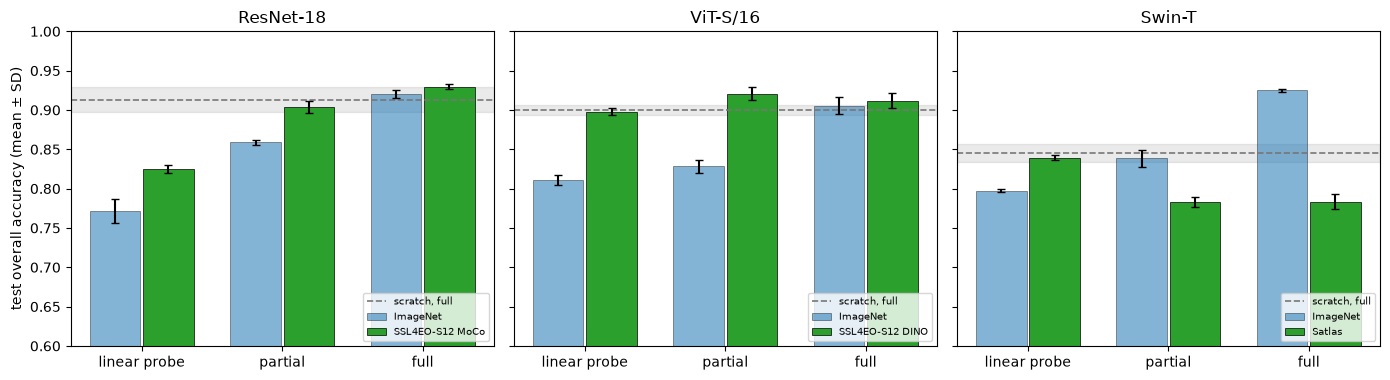

In [11]:
# mean and spread per family, weights and mode
agg = bench.groupby(["family", "weights", "mode"], sort=False).agg(trainable=("trainable", "first"), val_acc=("val_acc", "mean"), test_oa=("test_oa", "mean"), test_oa_sd=("test_oa", "std"),
                                                                    test_f1=("test_f1", "mean"), test_f1_sd=("test_f1", "std"), runs=("seed", "count"), sec=("sec", "mean")).reset_index()
print(agg.round(4).to_string(index=False))  # show it

fams = ["ResNet-18", "ViT-S/16", "Swin-T"]  # the three model families
wcol = {"ImageNet": "#1f77b4", "SSL4EO-S12 MoCo": "#2ca02c", "SSL4EO-S12 DINO": "#2ca02c", "Satlas": "#2ca02c"}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)  # three panels
for a, fam in zip(ax, fams):  # one per family
    d = agg[agg.family == fam]  # its runs
    sc = d[d.weights == "scratch"].iloc[0]  # the from-scratch result
    a.axhline(sc.test_oa, color="#777", ls="--", lw=1.2, label="scratch, full"); a.axhspan(sc.test_oa - sc.test_oa_sd, sc.test_oa + sc.test_oa_sd, color="#777", alpha=0.15)
    wts = [w for w in d.weights.unique() if w != "scratch"]  # the pretrained weights
    for j, w in enumerate(wts):  # each weight set ...
        for i, mode in enumerate(["linear_probe", "partial", "full"]):  # ... and mode
            r = d[(d.weights == w) & (d["mode"] == mode)].iloc[0]  # its mean result
            # a bar with its spread
            a.bar(i + (j - 0.5) * 0.38, r.test_oa, 0.36, yerr=r.test_oa_sd, color=wcol[w], alpha=0.55 if w == "ImageNet" else 1.0, capsize=3, label=w if i == 0 else None, edgecolor="k", lw=0.5)
    # labels, title, limits and legend
    a.set_xticks(range(3)); a.set_xticklabels(["linear probe", "partial", "full"]); a.set_title(fam); a.set_ylim(0.6, 1.0); a.legend(fontsize=7, loc="lower right")
ax[0].set_ylabel("test overall accuracy (mean ± SD)")  # y label
plt.tight_layout(); plt.show()  # arrange and draw

### Per-class view and statistical care

Overall accuracy on a balanced pool is the mean of the per-class recalls. The per-class F1 of the best ViT-S and the scratch ViT-S show which classes pretraining helps. Differences between two configurations are only meaningful when they exceed the seed-to-seed SD in the table above.


In [12]:
pc = {}  # per-class F1 of each ViT
# the three kept ViT models
for key, lbl in [(("vits_scratch", "full"), "ViT-S scratch"), (("vits_imagenet", "full"), "ViT-S ImageNet"), (("vits_ssl4eo", "full"), "ViT-S SSL4EO")]:
    m = KEEP[key]; dk = ARCH[key[0]][3]  # the model and its input recipe
    # test predictions
    p = ic.predict_proba_batches(m, ic.as_loader(DATASETS[dk](te), 256, shuffle=False), batch_size=256, device=DEVICE).argmax(1)
    # test report with bootstrap
    rep = ic.classification_report(y[te], p, class_names=dict(enumerate(CLASSES)), n_boot=300)
    pc[lbl] = rep["per_class"]["f1"]  # per-class F1
    # headline scores
    print(f"{lbl:16s} OA {rep['overall_accuracy']:.3f} | kappa {rep['kappa']:.3f} | macro-F1 {rep['macro_f1']:.3f}")
print(pd.DataFrame(pc).round(3))  # per-class table

ViT-S scratch    OA 0.903 | kappa 0.875 | macro-F1 0.810


ViT-S ImageNet   OA 0.914 | kappa 0.890 | macro-F1 0.849


ViT-S SSL4EO     OA 0.919 | kappa 0.896 | macro-F1 0.848
                ViT-S scratch  ViT-S ImageNet  ViT-S SSL4EO
Corn                    0.966           0.955         0.969
Soybeans                0.972           0.968         0.978
Grass/pasture           0.782           0.801         0.846
Developed               0.873           0.906         0.877
Wetland/forest          0.931           0.935         0.916
Other                   0.333           0.531         0.500


## What a Vision Transformer looks at: attention rollout

In a ViT the class token $\mathbf z^0$ gathers information from the patch tokens through attention. The raw attention of one layer says little, since the information is mixed again in the next layers. **Attention rollout** (Abnar & Zuidema, 2020) follows the flow through all layers. For layer $\ell$ take the head-averaged attention $\bar A^{\ell}$, add the residual connection as an identity matrix and renormalise the rows,

$$ \tilde A^{\ell}=\mathrm{rownorm}\Big(\tfrac12\big(\bar A^{\ell}+I\big)\Big),\qquad R=\tilde A^{L}\,\tilde A^{L-1}\cdots\tilde A^{1}, $$

and read the row of the class token, $R_{0,\,1:N+1}$, as an importance map over the $14\times14$ patch grid. `vit_attention_rollout(model, x, discard_ratio=0, head_fusion="mean")` implements this for timm ViTs (`discard_ratio` removes the weakest attention weights, `head_fusion="max"` keeps the strongest head).

**Read it cautiously.** Attention shows *where the class token reads from*, not a causal explanation of the prediction. We therefore add one quantitative check using the CDL labels: for **mixed chips** (majority class below 90 % of the chip) that the model classifies correctly we measure the share of the rollout mass that falls on pixels of the true class, divided by the area share of that class. A ratio above 1 means that the model reads preferentially from the pixels of the class it predicts.


rollout grid: (14, 14) tokens | chip (16, 16) px


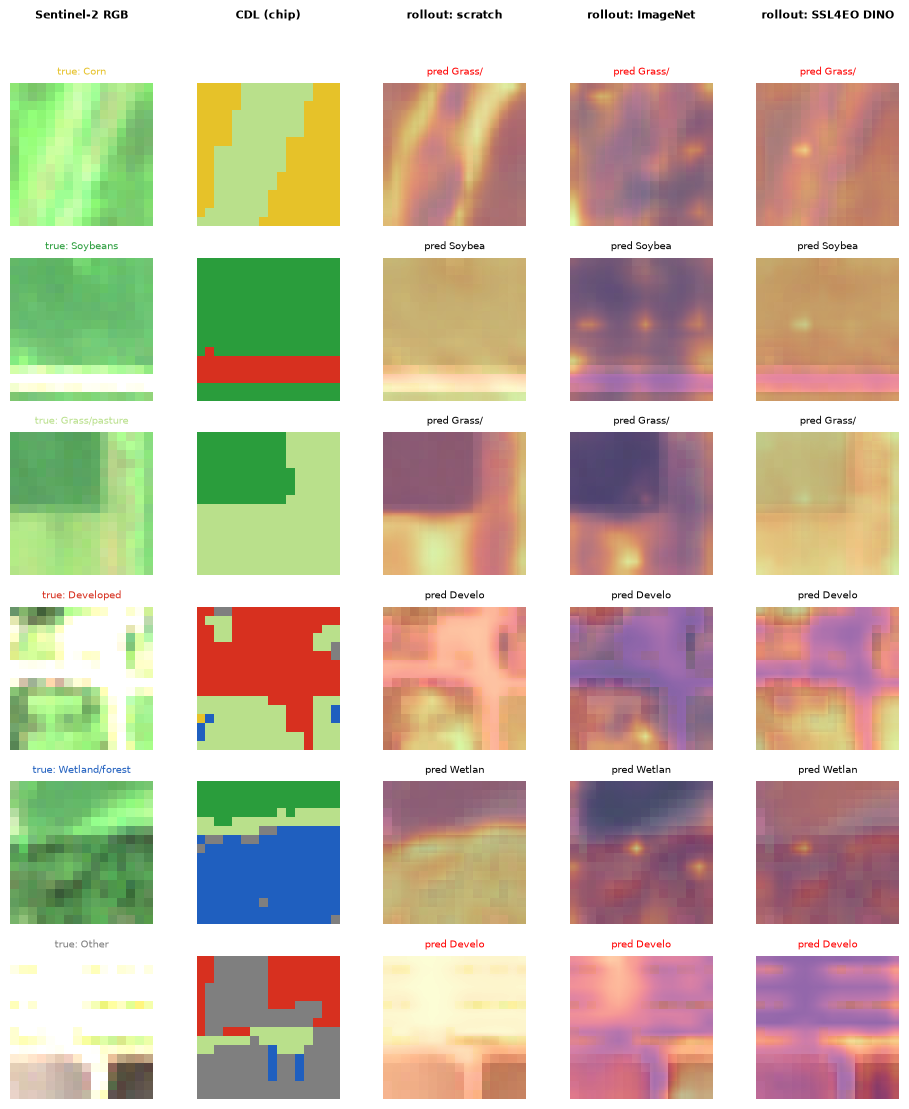

      model  mixed_correct_chips  mass_on_true_class_pixels_vs_area    se  normalised_entropy
    scratch                  572                              1.039 0.003               0.997
   ImageNet                  581                              0.994 0.004               0.993
SSL4EO DINO                  583                              0.986 0.002               0.998


In [13]:
def rollout(name, mode, idx):  # attention rollout of a kept ViT on chips idx
    m = KEEP[(name, mode)]; dk = ARCH[name][3]  # the model and its input recipe
    ds = DATASETS[dk](idx)  # the chips
    rs, ps = [], []  # rollout maps and predictions
    for s0 in range(0, len(ds), 64):  # batches of 64
        # the batch on the device
        xb = torch.stack([ds[i]["image"] for i in range(s0, min(s0 + 64, len(ds)))]).to(DEVICE)
        with torch.no_grad():  # no gradients needed
            ps.append(m(xb).argmax(1).cpu().numpy())  # predictions
        rs.append(ic.vit_attention_rollout(m, xb)); del xb  # attention rollout of the batch
        torch.cuda.empty_cache()  # free GPU memory
    r, pred = np.concatenate(rs), np.concatenate(ps)  # all batches together
    # upsampled to 16 x 16 pixels
    r16 = F.interpolate(torch.from_numpy(r)[:, None], size=(SIZE, SIZE), mode="bilinear", align_corners=False)[:, 0].numpy()
    return r, r16, pred  # token maps, pixel maps and predictions

# the three ViT models
names = [("vits_scratch", "scratch"), ("vits_imagenet", "ImageNet"), ("vits_ssl4eo", "SSL4EO DINO")]
RO = {n_: rollout(n_, "full", te) for n_, _ in names}  # rollout of each on the test chips
# token grid and chip size
print("rollout grid:", RO["vits_ssl4eo"][0].shape[1:], "tokens | chip", (SIZE, SIZE), "px")

# six test chips: one per class, preferring mixed chips
rng = np.random.default_rng(3)
show = []  # chips to show
for k in range(K):  # each class
    # test chips of that class, preferring mixed chips
    c = np.flatnonzero((y[te] == k) & (pur[te] < 0.9)); c = c if len(c) else np.flatnonzero(y[te] == k)
    show.append(int(rng.choice(c)))  # one random chip
fig, ax = plt.subplots(K, 5, figsize=(9.5, 1.85 * K))  # one row per chip
for r_, i in enumerate(show):  # each chip
    ax[r_, 0].imshow(rgb(np.moveaxis(X[te][i][[2, 1, 0]], 0, -1)), interpolation="nearest")  # true colour
    # its CDL labels
    ax[r_, 1].imshow(np.where(M[te][i] < 0, np.nan, M[te][i]), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
    for c_, (n_, lbl) in enumerate(names):  # each ViT
        # true colour underneath
        ax[r_, 2 + c_].imshow(rgb(np.moveaxis(X[te][i][[2, 1, 0]], 0, -1)), interpolation="nearest")
        # its rollout map on top
        ax[r_, 2 + c_].imshow(RO[n_][1][i], cmap="magma", alpha=0.65, vmin=0, vmax=1, interpolation="bilinear")
        # predicted class (red if wrong)
        ax[r_, 2 + c_].set_title(f"pred {CLASSES[RO[n_][2][i]][:6]}", fontsize=7, color="k" if RO[n_][2][i] == y[te][i] else "r")
    for a in ax[r_]: a.axis("off")  # no axes
    ax[r_, 0].set_title(f"true: {CLASSES[y[te][i]]}", fontsize=7, color=COLORS[y[te][i]])  # true class
# column headers
for c_, t in enumerate(["Sentinel-2 RGB", "CDL (chip)", "rollout: scratch", "rollout: ImageNet", "rollout: SSL4EO DINO"]):
    # ...
    ax[0, c_].annotate(t, (0.5, 1.45), xycoords="axes fraction", ha="center", fontsize=8, fontweight="bold")
plt.tight_layout(); plt.show()  # arrange and draw

rows = []  # one row per model
for n_, lbl in names:  # each ViT
    r16, pred = RO[n_][1], RO[n_][2]  # its pixel maps and predictions
    sel_ = np.flatnonzero((pred == y[te]) & (pur[te] < 0.9))  # mixed test chips it classified correctly
    ratio, ent = [], []  # attention mass ratio and entropy per chip
    for i in sel_:  # each chip
        # pixels of the true class; normalised attention
        inside = (M[te][i] == y[te][i]); w = r16[i] / r16[i].sum()
        ratio.append(w[inside].sum() / inside.mean())  # attention on those pixels relative to their area
        ent.append(-(w * np.log(w + 1e-12)).sum() / np.log(w.size))  # normalised entropy of the attention
    # means and standard errors
    rows.append(dict(model=lbl, mixed_correct_chips=len(sel_), mass_on_true_class_pixels_vs_area=np.mean(ratio), se=np.std(ratio) / np.sqrt(len(ratio)), normalised_entropy=np.mean(ent)))
print(pd.DataFrame(rows).round(3).to_string(index=False))  # show them

## Label-budget curves

The most important question for an operational project is: **how many labelled chips do we need?** For each *budget* $n$ the training set is a class-stratified random subset of the training chips (at least two chips per class); validation and test sets are unchanged. To be honest about a small label budget, **no validation set is used for these runs** (a large validation set would be a hidden source of labels): hyper-parameters are those fixed in the *More than three bands: adapting the input layer* section, and the model after the last epoch is evaluated. The number of epochs is increased for small $n$ so that every run sees a similar number of gradient steps, $\text{epochs}=\min(25,\max(6,\lceil 6\,n_{\text{full}}/n\rceil))$.


In [14]:
BUDGETS = [32, 96, 256, 640, 1600, len(tr)]  # numbers of training chips to test
def subset(n, seed):  # a class-proportional subset of n training chips
    if n >= len(tr):  # the full budget
        return tr  # all training chips
    r = np.random.default_rng(1000 + seed)  # a generator per seed
    # at least two chips per class, in proportion
    out = [r.choice(tr[y[tr] == k], min(max(2, round(n * (y[tr] == k).sum() / len(tr))), (y[tr] == k).sum()), replace=False) for k in range(K)]
    return np.concatenate(out)  # the subset

def budget_run(name, mode, n, seed):  # train one model on n chips
    idx = subset(n, seed)  # the subset
    ep = int(np.clip(np.ceil(EPOCHS * len(tr) / len(idx)), EPOCHS, 25))  # more epochs for smaller subsets
    # train without a validation set
    r, _ = run(name, mode, seed, idx=idx, epochs=ep, val=False, bs=int(min(64, max(8, len(idx) // 8))))
    r["budget"] = n; return r  # record the budget

# the ResNet-18 runs
ARMS_R18 = [("r18_scratch", "full"), ("r18_imagenet", "linear_probe"), ("r18_imagenet", "partial"), ("r18_imagenet", "full"),
            ("r18_ssl4eo", "linear_probe"), ("r18_ssl4eo", "partial"), ("r18_ssl4eo", "full")]
# the ViT runs
ARMS_VIT = [("vits_scratch", "full"), ("vits_imagenet", "linear_probe"), ("vits_imagenet", "full"), ("vits_ssl4eo", "linear_probe"), ("vits_ssl4eo", "full")]
bud_rows = []  # one row per run
t00 = time.time()  # start the timer
for arms, seeds in [(ARMS_R18, SEEDS), (ARMS_VIT, SEEDS[:2])]:  # both families
    for name, mode in arms:  # each model and mode
        for n in BUDGETS:  # each budget
            for s in seeds:  # each seed
                bud_rows.append(budget_run(name, mode, n, s))  # train and collect
        d = pd.DataFrame(bud_rows).query("model == @name and mode == @mode")  # runs of this model and mode
        # progress line
        print(f"{ARCH[name][0]:26s} {mode:13s}", " ".join(f"{n}:{d[d.budget == n].test_oa.mean():.3f}" for n in BUDGETS), f"| {(time.time()-t00)/60:.1f} min", flush=True)
bud = pd.DataFrame(bud_rows)  # as a table

ResNet-18 / scratch        full          32:0.699 96:0.767 256:0.864 640:0.884 1600:0.919 3821:0.924 | 1.2 min


ResNet-18 / ImageNet       linear_probe  32:0.560 96:0.685 256:0.730 640:0.768 1600:0.766 3821:0.782 | 1.6 min


ResNet-18 / ImageNet       partial       32:0.687 96:0.769 256:0.806 640:0.830 1600:0.840 3821:0.861 | 2.3 min


ResNet-18 / ImageNet       full          32:0.719 96:0.793 256:0.837 640:0.863 1600:0.905 3821:0.916 | 3.5 min


ResNet-18 / SSL4EO MoCo    linear_probe  32:0.667 96:0.746 256:0.808 640:0.811 1600:0.821 3821:0.822 | 4.0 min


ResNet-18 / SSL4EO MoCo    partial       32:0.803 96:0.834 256:0.873 640:0.894 1600:0.911 3821:0.913 | 4.7 min


... (2 outputs left out)

ViT-S/16 / ImageNet        linear_probe  32:0.631 96:0.707 256:0.765 640:0.788 1600:0.805 3821:0.813 | 12.4 min


ViT-S/16 / ImageNet        full          32:0.659 96:0.745 256:0.842 640:0.883 1600:0.909 3821:0.914 | 17.1 min


ViT-S/16 / SSL4EO DINO     linear_probe  32:0.772 96:0.832 256:0.858 640:0.864 1600:0.896 3821:0.903 | 19.0 min


ViT-S/16 / SSL4EO DINO     full          32:0.766 96:0.844 256:0.889 640:0.923 1600:0.925 3821:0.932 | 23.7 min


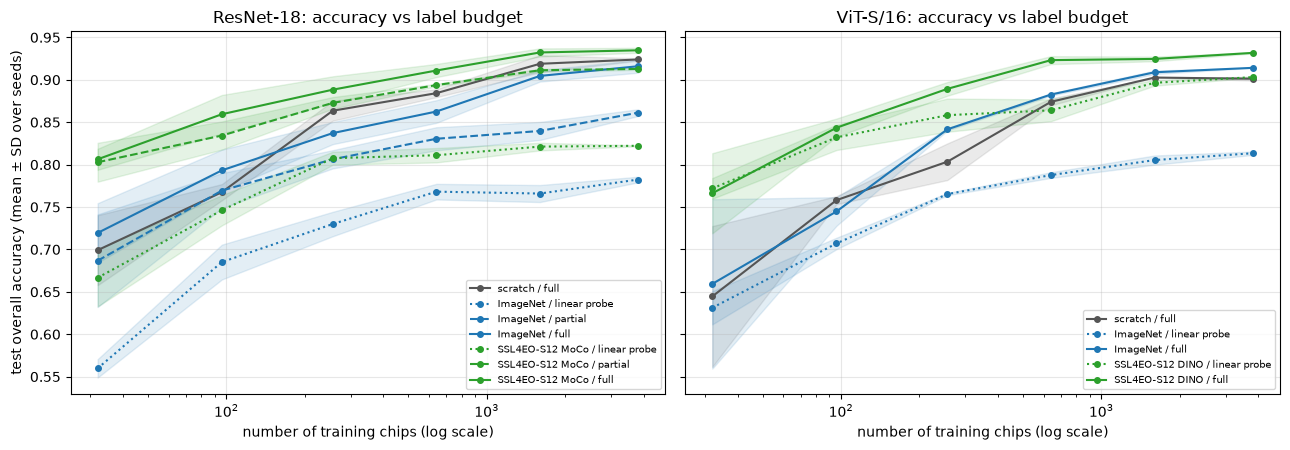


ResNet-18: test OA (mean±SD) by number of training chips
budget                                 32           96           256          640          1600         3821
arm                                                                                                         
ImageNet / full                 0.719±0.035  0.793±0.024  0.837±0.013  0.863±0.013  0.905±0.007  0.916±0.008
ImageNet / linear_probe         0.560±0.011  0.685±0.021  0.730±0.014  0.768±0.009  0.766±0.010  0.782±0.003
ImageNet / partial              0.687±0.055  0.769±0.021  0.806±0.011  0.830±0.014  0.840±0.011  0.861±0.004
SSL4EO-S12 MoCo / full          0.806±0.012  0.859±0.023  0.888±0.016  0.911±0.008  0.932±0.005  0.935±0.003
SSL4EO-S12 MoCo / linear_probe  0.667±0.034  0.746±0.018  0.808±0.008  0.811±0.008  0.821±0.005  0.822±0.001
SSL4EO-S12 MoCo / partial       0.803±0.023  0.834±0.017  0.873±0.007  0.894±0.001  0.911±0.002  0.913±0.001
scratch / full                  0.699±0.041  0.767±0.010  0.864±0.012 

In [15]:
bud["arm"] = bud.weights + " / " + bud["mode"]  # weights / mode label
stl = {"linear_probe": ":", "partial": "--", "full": "-"}  # line style per mode
colr = {"scratch": "#555555", "ImageNet": "#1f77b4", "SSL4EO-S12 MoCo": "#2ca02c", "SSL4EO-S12 DINO": "#2ca02c"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)  # two panels
for a, fam in zip(ax, ["ResNet-18", "ViT-S/16"]):  # one per family
    # each weights and mode
    for (w, mode), d in bud[bud.family == fam].groupby(["weights", "mode"], sort=False):
        g = d.groupby("budget").test_oa.agg(["mean", "std"]).reindex(BUDGETS)  # mean and spread per budget
        # the mean curve
        a.plot(g.index, g["mean"], stl[mode], color=colr[w], marker="o", ms=4, label=f"{w} / {mode.replace('_', ' ')}")
        # the spread band
        a.fill_between(g.index, g["mean"] - g["std"].fillna(0), g["mean"] + g["std"].fillna(0), color=colr[w], alpha=0.12)
    # log axis, labels, title, grid and legend
    a.set_xscale("log"); a.set_xlabel("number of training chips (log scale)"); a.set_title(f"{fam}: accuracy vs label budget"); a.grid(alpha=0.3); a.legend(fontsize=7, loc="lower right")
ax[0].set_ylabel("test overall accuracy (mean ± SD over seeds)")  # y label
plt.tight_layout(); plt.show()  # arrange and draw

for fam in ["ResNet-18", "ViT-S/16"]:  # each family
    # mean ± SD per arm and budget
    t = bud[bud.family == fam].groupby(["arm", "budget"]).test_oa.agg(["mean", "std"]).apply(lambda r: f"{r['mean']:.3f}±{0 if np.isnan(r['std']) else r['std']:.3f}", axis=1).unstack("budget")
    # header and table
    print(f"\n{fam}: test OA (mean±SD) by number of training chips"); print(t[BUDGETS].to_string())

def chips_to_reach(fam, thr):  # smallest budget that reaches an accuracy threshold
    out = {}  # one value per arm
    for arm, d in bud[bud.family == fam].groupby("arm"):  # each arm
        g = d.groupby("budget").test_oa.mean().reindex(BUDGETS)  # mean accuracy per budget
        hit = g[g >= thr]  # budgets at or above the threshold
        out[arm] = int(hit.index[0]) if len(hit) else np.nan  # the first of them
    return pd.Series(out)  # as a Series
print("\nsmallest tested budget reaching a mean test OA of 0.80 / 0.85 / 0.90 (NaN = not reached):")  # header
# the table
print(pd.DataFrame({f"{fam} >={t:.2f}": chips_to_reach(fam, t) for fam in ["ResNet-18", "ViT-S/16"] for t in (0.80, 0.85, 0.90)}).to_string())

## Summary of the experiments


In [16]:
print("Transfer-mode benchmark (full training set; test OA mean ± SD, macro-F1):")  # header
# accuracy with its spread and macro F1
t = agg.assign(OA=lambda d: d.test_oa.map("{:.3f}".format) + "±" + d.test_oa_sd.fillna(0).map("{:.3f}".format), F1=lambda d: d.test_f1.map("{:.3f}".format))
# the summary table
print(t[["family", "weights", "mode", "trainable", "OA", "F1", "runs", "sec"]].round(1).to_string(index=False))
# the stem comparison
print("\nStem adaptation (ResNet-18 ImageNet, full fine-tuning):"); print(stem_tab.round(4).to_string())
# accuracy with the second-smallest budget
small = bud[bud.budget == BUDGETS[1]].groupby(["family", "arm"]).test_oa.agg(["mean", "std"]).round(3)
print(f"\nAccuracy with only {BUDGETS[1]} training chips:"); print(small.to_string())  # show it

Transfer-mode benchmark (full training set; test OA mean ± SD, macro-F1):
   family         weights         mode  trainable          OA    F1  runs   sec
ResNet-18         scratch         full   11201542 0.913±0.016 0.852     3   7.2
ResNet-18        ImageNet linear_probe       3078 0.771±0.015 0.689     3   3.0
ResNet-18        ImageNet      partial    8396806 0.859±0.003 0.776     3   4.1
ResNet-18        ImageNet         full   11201542 0.920±0.005 0.862     3   7.2
ResNet-18 SSL4EO-S12 MoCo linear_probe       3078 0.825±0.005 0.746     3   3.0
ResNet-18 SSL4EO-S12 MoCo      partial    8396806 0.904±0.008 0.832     3   4.2
ResNet-18 SSL4EO-S12 MoCo         full   11201542 0.930±0.003 0.886     3   7.2
 ViT-S/16         scratch         full   22356102 0.899±0.006 0.813     3  44.9
 ViT-S/16        ImageNet linear_probe       2310 0.811±0.007 0.733     3  18.7
 ViT-S/16        ImageNet      partial    1777542 0.828±0.008 0.746     3  20.5
 ViT-S/16        ImageNet         full   22356

## AOI-only fine-tuning and prediction beyond the AOI

The benchmark above selects **SSL4EO-S12 MoCo ResNet-18, fully fine-tuned**: it had the strongest mean test OA in the model comparison (0.931 ± 0.001). Here we fit that recipe using only labelled chips fully contained by the AOI, then apply a three-seed ensemble at valid Sentinel-2 pixel centers outside it. This keeps the prediction region spatially separate from the training labels.

Each prediction uses a 16 × 16 input chip (160 m at 10 m pixels), centered on one 10 m output pixel. This is center-based sliding-window classification, not semantic segmentation: the output grid is 10 m, but each label uses a 160 m context window and may blur boundaries. The AOI boundary is rasterized in the image CRS; only pixels outside it are included in the reported areas. Cloud/shadow/nodata pixels and locations without a valid neighboring chip remain unclassified. At the outer raster edge, reflected padding supplies the missing context window.

For class \(k\), the mapped area is \(A_k = N_k\,|r_x r_y|/10^4\) hectares, where \(N_k\) is the number of classified 10 m pixels assigned class \(k\), and \(r_x,r_y\) are the raster pixel dimensions in metres. CDL outside the AOI is shown only as a model-product comparison, not independent ground truth.


AOI raster coverage: 97.82% | outside scene footprint: 192,786 pixels (1,927.9 ha)


AOI-only chip pool: 5791 | per-class: {'Corn': 1190, 'Soybeans': 1187, 'Grass/pasture': 1168, 'Developed': 807, 'Wetland/forest': 1024, 'Other': 415} | spatial blocks: 121


AOI spatial hold-out (whole blocks): OA 0.934 | macro-F1 0.886


Final AOI-only ensemble: 3 SSL4EO ResNet-18 models, 6 epochs each


Outside clear pixels: 191,197 | mapped: 190,149 (99.5%) | output grid: 10 m; chip context: 160 m
Predicted area outside AOI (clear/mapped pixels only; CDL columns use the same CDL-valid subset):
         class  predicted_ha_clear  predicted_ha_CDL_valid  CDL_ha_CDL_valid
          Corn              860.56                  722.32            699.93
      Soybeans              722.57                  520.39            479.12
 Grass/pasture              147.79                  107.46            103.26
     Developed               73.36                   68.04            141.67
Wetland/forest               66.33                   49.09             42.85
         Other               30.88                   26.50             26.97
Unclassified clear exterior: 1,048 pixels | cloud/shadow/nodata exterior: 1,589 pixels
Agreement with outside-AOI CDL (not independent ground truth): OA 0.866 | macro-F1 0.687 | n=149,380


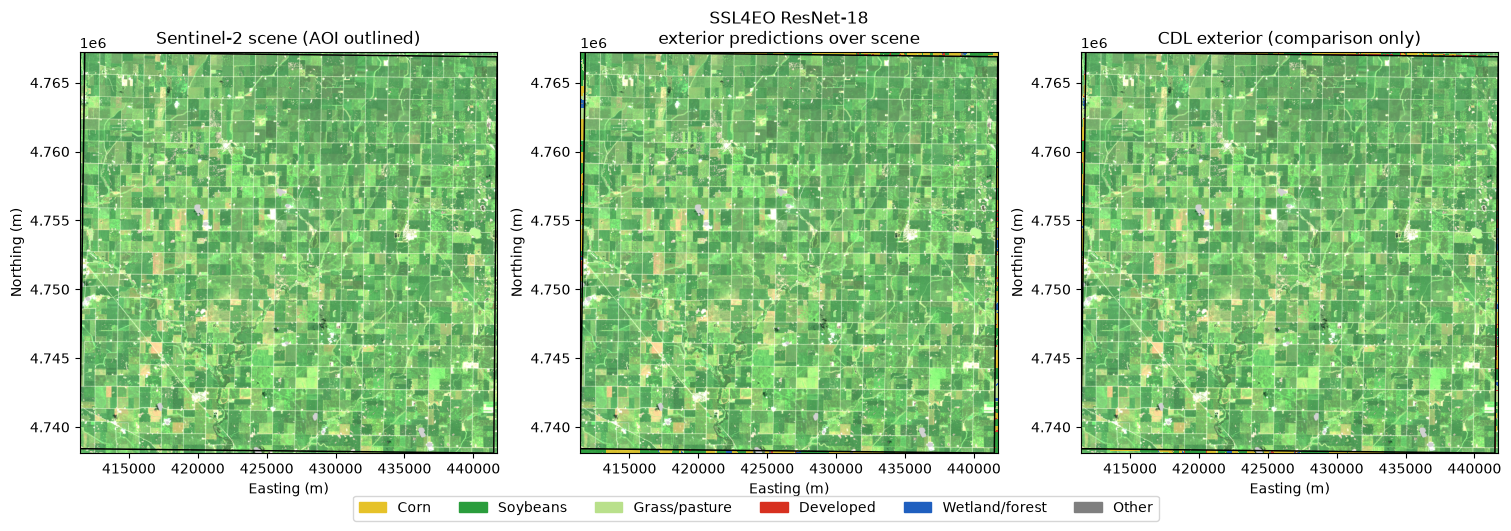

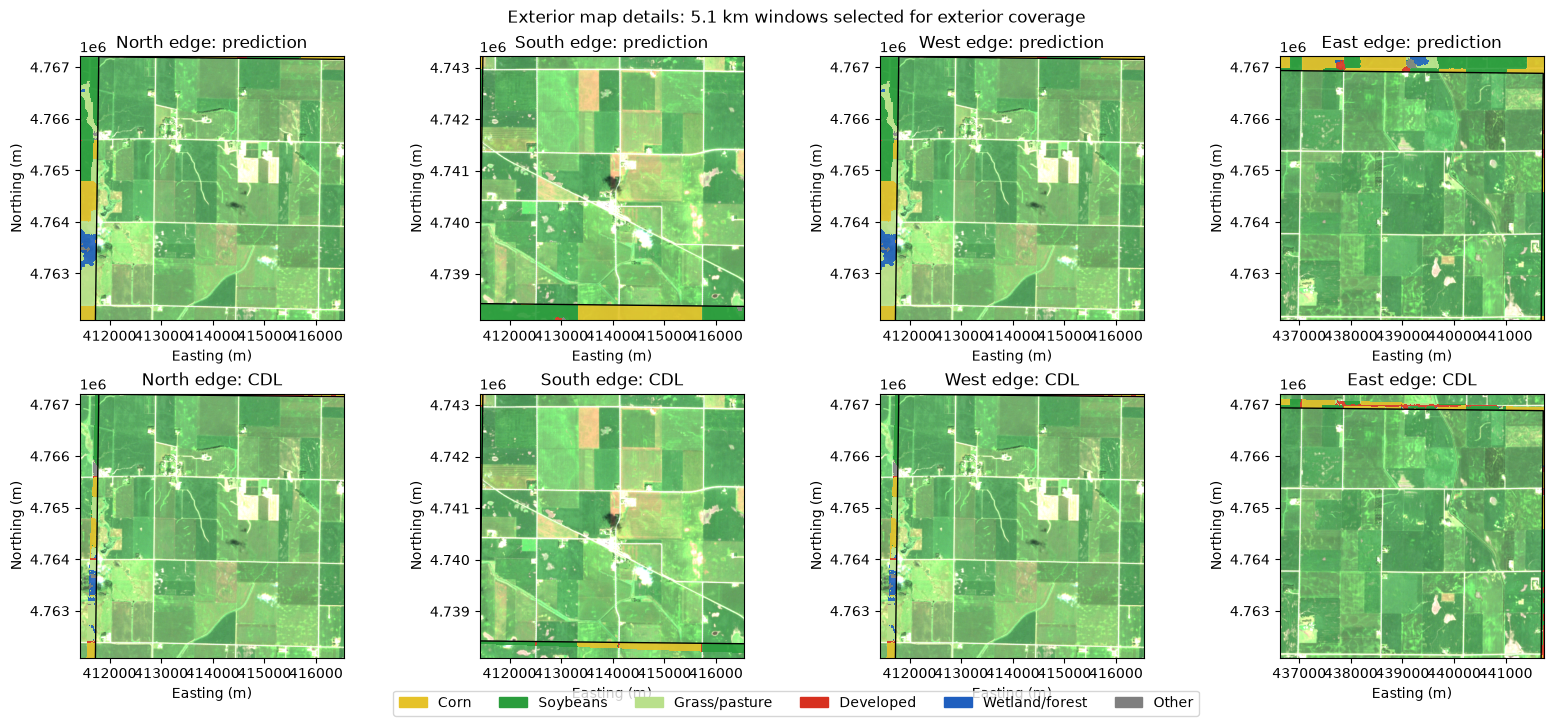

In [17]:
from rasterio.features import geometry_mask  # rasterise a polygon
from rasterio.warp import transform_geom  # reproject a geometry
from rasterio.transform import rowcol  # map coordinates -> row and column
# distance to the nearest pixel (kept from the original workflow)
from scipy.ndimage import distance_transform_edt

# Rasterize the AOI on the exact Sentinel-2 grid. The AOI GeoJSON is lon/lat.
geom_wgs84 = aoi["geometry"] if aoi["type"] == "Feature" else aoi
geom_map = transform_geom("EPSG:4326", ref.rio.crs, geom_wgs84)  # the AOI in the scene CRS
H, W = refl.shape[1:]  # scene size
# pixels inside the AOI
inside_aoi = geometry_mask([geom_map], out_shape=(H, W), transform=ref.rio.transform(), invert=True)
valid_pixel = np.isfinite(refl.values).all(axis=0)  # pixels with all ten bands
outside_valid = (~inside_aoi) & valid_pixel  # clear pixels outside the AOI
pixel_m2 = abs(float(ref.rio.resolution()[0] * ref.rio.resolution()[1]))  # pixel area in m2
outside_geometry_ha = int((~inside_aoi).sum()) * pixel_m2 / 10_000  # area outside the AOI in hectares
# coverage and outside area
print(f"AOI raster coverage: {inside_aoi.mean():.2%} | outside scene footprint: {(~inside_aoi).sum():,} pixels ({outside_geometry_ha:,.1f} ha)")

# X/y are the existing class-balanced chip pool. xy and sel preserve each selected
# chip's map coordinate; require every pixel in its 16x16 label chip to be inside AOI.
xy_selected = np.asarray(xy)[sel]
# row and column of every chip centre
chip_rows, chip_cols = rowcol(ref.rio.transform(), xy_selected[:, 0], xy_selected[:, 1])
chip_rows, chip_cols = np.asarray(chip_rows), np.asarray(chip_cols)  # as arrays
r0, c0 = chip_rows - SIZE // 2, chip_cols - SIZE // 2  # top-left corner of every chip
# summed-area table of the AOI mask
inside_sum = np.pad(inside_aoi.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
contained = ((r0 >= 0) & (c0 >= 0) & (r0 + SIZE <= H) & (c0 + SIZE <= W))  # chips fully inside the scene
contained_idx = np.flatnonzero(contained)  # their indices
r, c = r0[contained_idx], c0[contained_idx]  # their corners
contained[contained_idx] &= (  # a chip is kept when all its pixels are inside the AOI
    inside_sum[r + SIZE, c + SIZE] - inside_sum[r, c + SIZE]
    - inside_sum[r + SIZE, c] + inside_sum[r, c] == SIZE * SIZE
)
aoi_idx = np.flatnonzero(contained)  # chips fully inside the AOI
X_aoi, y_aoi, groups_aoi = X[aoi_idx], y[aoi_idx], groups[aoi_idx]  # their chips, labels and blocks
counts_aoi = np.bincount(y_aoi, minlength=K)  # chips per class
if len(aoi_idx) < 100 or np.any(counts_aoi == 0):  # too few chips or a class missing
    # stop with a clear message
    raise ValueError(f"Not enough AOI-contained labelled chips to train all classes: {counts_aoi.tolist()}")
# pool size, classes and blocks
print("AOI-only chip pool:", len(aoi_idx), "| per-class:", dict(zip(CLASSES, counts_aoi.tolist())),
      "| spatial blocks:", len(np.unique(groups_aoi)))

# Check the chosen recipe on a held-out set of entire AOI blocks before final fitting.
aoi_split = ic.group_split(groups_aoi, test_size=0.2, val_size=0.2, seed=SEED)
# training chips (raw reflectance, SSL4EO convention)
train_ds = ic.ChipDataset(X_aoi[aoi_split.train], y_aoi[aoi_split.train])
val_ds = ic.ChipDataset(X_aoi[aoi_split.val], y_aoi[aoi_split.val])  # validation chips
test_ds = ic.ChipDataset(X_aoi[aoi_split.test], y_aoi[aoi_split.test])  # test chips
train_loader = ic.as_loader(train_ds, 64, shuffle=True, seed=SEED, drop_last=True)  # training batches
val_loader = ic.as_loader(val_ds, 256, shuffle=False)  # validation batches
test_loader = ic.as_loader(test_ds, 256, shuffle=False)  # test batches
check_model = make("r18_ssl4eo")  # the SSL4EO ResNet-18
ic.set_trainable(check_model, "full")  # train every layer
ic.train_model(check_model, train_loader, val_loader, epochs=EPOCHS, lr=LR["full"],  # train with early stopping
               precision="16" if DEVICE == "cuda" else "32", early_stopping=2,
               seed=SEED, device=DEVICE, verbose=False)
# test probabilities
test_prob = ic.predict_proba_batches(check_model, test_loader, batch_size=256, device=DEVICE)
test_pred = test_prob.argmax(1)  # test classes
test_report = ic.classification_report(y_aoi[aoi_split.test], test_pred)  # test report
# its scores
print(f"AOI spatial hold-out (whole blocks): OA {test_report['overall_accuracy']:.3f} | macro-F1 {test_report['macro_f1']:.3f}")
del check_model, train_loader, val_loader, test_loader, test_prob, test_pred  # free memory
if DEVICE == "cuda": torch.cuda.empty_cache()  # and the GPU cache

# Refit three independently seeded models on every AOI-contained chip; average
# their probabilities for the outside-AOI map.
final_models = []
all_loader = None  # the training loader of the current seed
for seed in [0, 1, 2]:  # three seeds
    ic.set_seed(seed)  # reproducible initialisation
    model = make("r18_ssl4eo")  # a fresh model
    ic.set_trainable(model, "full")  # train every layer
    # all AOI chips
    all_loader = ic.as_loader(ic.ChipDataset(X_aoi, y_aoi), 64, shuffle=True, seed=seed, drop_last=True)
    ic.train_model(model, all_loader, epochs=EPOCHS, lr=LR["full"],  # train on them
                   precision="16" if DEVICE == "cuda" else "32", seed=seed,
                   device=DEVICE, verbose=False)
    model.eval()  # evaluation mode
    final_models.append(model)  # keep it
    del all_loader  # free the loader
    if DEVICE == "cuda": torch.cuda.empty_cache()  # and the GPU cache
# ensemble size
print(f"Final AOI-only ensemble: {len(final_models)} SSL4EO ResNet-18 models, {EPOCHS} epochs each")

# Predict each valid 10 m pixel center outside the AOI using a 16x16 context chip.
# Reflect-pad the scene edge so valid border pixels can also receive predictions.
pad = SIZE // 2
# reflect-pad the scene
cube = np.pad(np.asarray(refl.values, dtype=np.float32), ((0, 0), (pad, pad), (pad, pad)), mode="reflect")
valid_padded = np.pad(valid_pixel, ((pad, pad), (pad, pad)), mode="reflect")  # and the validity mask
# summed-area table of valid pixels
valid_sum = np.pad(valid_padded.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))
center_rows, center_cols = np.nonzero(outside_valid)  # clear pixels outside the AOI
chip_rows, chip_cols = center_rows.copy(), center_cols.copy()  # their chip corners in the padded scene
# a chip is usable when all its pixels are valid
window_valid = (valid_sum[chip_rows + SIZE, chip_cols + SIZE] - valid_sum[chip_rows, chip_cols + SIZE]
                - valid_sum[chip_rows + SIZE, chip_cols] + valid_sum[chip_rows, chip_cols]) == SIZE * SIZE
center_rows, center_cols = center_rows[window_valid], center_cols[window_valid]  # keep usable centres
chip_rows, chip_cols = chip_rows[window_valid], chip_cols[window_valid]  # and their corners
if len(center_rows) == 0:  # nothing to map
    raise ValueError("No valid Sentinel-2 chips have centers outside the AOI.")  # stop with a clear message

pred_map = np.full((H, W), 255, dtype=np.uint8)  # 255 = not mapped
for start in range(0, len(center_rows), 256):  # batches of 256 chips
    br, bc = center_rows[start:start + 256], center_cols[start:start + 256]  # centres of the batch
    rr, cc = chip_rows[start:start + 256], chip_cols[start:start + 256]  # corners of the batch
    xb = np.stack([cube[:, r:r + SIZE, c:c + SIZE] for r, c in zip(rr, cc)])  # the chips
    tx = torch.from_numpy(xb).to(DEVICE)  # as a tensor on the device
    probs = []  # probabilities of each model
    with torch.inference_mode():  # inference only
        for model in final_models:  # each ensemble member
            probs.append(torch.softmax(model(tx), dim=1).float().cpu().numpy())  # its class probabilities
    pred_map[br, bc] = np.mean(probs, axis=0).argmax(axis=1).astype(np.uint8)  # mean probability -> class
    del xb, tx, probs  # free memory
mapped = pred_map != 255  # mapped pixels
coverage = mapped.sum() / max(outside_valid.sum(), 1)  # share of the clear exterior that was mapped
# counts, coverage and context size
print(f"Outside clear pixels: {outside_valid.sum():,} | mapped: {mapped.sum():,} ({coverage:.1%}) | output grid: 10 m; chip context: {SIZE * pixel_m2**0.5:.0f} m")
if mapped.sum() == 0:  # nothing mapped
    # stop with a clear message
    raise ValueError("No valid outside-AOI pixels were covered by the chip predictions.")

# Area totals are for mapped, clear pixels only; report the remaining clear area as unclassified.
pred_counts = np.bincount(pred_map[mapped], minlength=K)
cdl_valid = mapped & (lab >= 0)  # mapped pixels with a CDL label
pred_cdl_counts = np.bincount(pred_map[cdl_valid], minlength=K)  # predicted classes on those pixels
cdl_counts = np.bincount(lab[cdl_valid].astype(int), minlength=K)  # CDL classes on the same pixels
area_table = pd.DataFrame({  # predicted and CDL areas
    "class": CLASSES,
    "predicted_ha_clear": pred_counts * pixel_m2 / 10_000,
    "predicted_ha_CDL_valid": pred_cdl_counts * pixel_m2 / 10_000,
    "CDL_ha_CDL_valid": cdl_counts * pixel_m2 / 10_000,
})
# header
print("Predicted area outside AOI (clear/mapped pixels only; CDL columns use the same CDL-valid subset):")
print(area_table.round(2).to_string(index=False))  # the table
# unmapped clear and cloudy exterior pixels
print(f"Unclassified clear exterior: {outside_valid.sum() - mapped.sum():,} pixels | "
      f"cloud/shadow/nodata exterior: {(~inside_aoi).sum() - outside_valid.sum():,} pixels")
if cdl_valid.sum():  # CDL pixels to compare
    # agreement report
    cdl_agreement = ic.classification_report(lab[cdl_valid].astype(int), pred_map[cdl_valid].astype(int))
    # its scores
    print(f"Agreement with outside-AOI CDL (not independent ground truth): OA {cdl_agreement['overall_accuracy']:.3f} | macro-F1 {cdl_agreement['macro_f1']:.3f} | n={cdl_valid.sum():,}")

# Show the full scene as context; overlay mapped exterior pixels instead of
# masking the AOI interior, which otherwise leaves only a thin perimeter visible.
extent = (ref.rio.bounds()[0], ref.rio.bounds()[2], ref.rio.bounds()[1], ref.rio.bounds()[3])
rgb_img = rgb(np.moveaxis(refl.sel(band=["red", "green", "blue"]).values, 0, -1))  # true colour of the scene
rgb_img[~valid_pixel] = (0.82, 0.82, 0.82)  # grey where no data
pred_view = np.where(mapped, pred_map.astype(float), np.nan)  # prediction as an image
cdl_view = np.where(cdl_valid, lab.astype(float), np.nan)  # CDL as an image
fig, ax = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)  # three panels
# the scene
ax[0].imshow(rgb_img, extent=extent, origin="upper"); ax[0].set_title("Sentinel-2 scene (AOI outlined)")
ax[1].imshow(rgb_img, extent=extent, origin="upper")  # scene underneath
# the prediction on top
ax[1].imshow(pred_view, extent=extent, origin="upper", cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest", alpha=0.9)
ax[1].set_title("SSL4EO ResNet-18\nexterior predictions over scene")  # title
ax[2].imshow(rgb_img, extent=extent, origin="upper")  # scene underneath
# the CDL on top
ax[2].imshow(cdl_view, extent=extent, origin="upper", cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest", alpha=0.9)
ax[2].set_title("CDL exterior (comparison only)")  # title
for a_ in ax:  # every panel
    ring = geom_map["coordinates"][0]  # the AOI ring
    a_.plot([p[0] for p in ring], [p[1] for p in ring], color="black", linewidth=1.1)  # draw it
    # limits and labels
    a_.set_xlim(extent[0], extent[1]); a_.set_ylim(extent[2], extent[3]); a_.set_xlabel("Easting (m)"); a_.set_ylabel("Northing (m)")
    a_.set_aspect("equal")  # equal scale
# class legend entries
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k], label=CLASSES[k]) for k in range(K)]
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.05))  # the legend
plt.show()  # draw

# Full-scene overviews necessarily make the exterior class pixels very thin.
# Find one 512x512-pixel window with the most exterior pixels near each scene edge.
from scipy.ndimage import uniform_filter
window = 512  # window size in pixels
# share of exterior pixels around each pixel
outside_density = uniform_filter(outside_valid.astype(np.float32), size=window, mode="constant")
edge_regions = {  # four edge zones of the scene
    "North": np.indices((H, W))[0] < H // 3,
    "South": np.indices((H, W))[0] >= 2 * H // 3,
    "West": np.indices((H, W))[1] < W // 3,
    "East": np.indices((H, W))[1] >= 2 * W // 3,
}
windows = {}  # the chosen window per side
for side, region in edge_regions.items():  # each side
    score = np.where(region, outside_density, -1)  # density inside that zone only
    center_r, center_c = np.unravel_index(np.argmax(score), score.shape)  # its densest centre
    r0 = int(np.clip(center_r - window // 2, 0, H - window))  # window row
    c0 = int(np.clip(center_c - window // 2, 0, W - window))  # window column
    windows[side] = (r0, c0, r0 + window, c0 + window)  # store the window

fig, ax = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)  # two rows of four panels
for j, (side, (r0, c0, r1, c1)) in enumerate(windows.items()):  # each window
    x0 = extent[0] + c0 * abs(ref.rio.resolution()[0])  # left edge in map units
    x1 = extent[0] + c1 * abs(ref.rio.resolution()[0])  # right edge
    y1 = extent[3] - r0 * abs(ref.rio.resolution()[1])  # top edge
    y0 = extent[3] - r1 * abs(ref.rio.resolution()[1])  # bottom edge
    crop_extent = (x0, x1, y0, y1)  # the window extent
    ax[0, j].imshow(rgb_img[r0:r1, c0:c1], extent=crop_extent, origin="upper")  # scene underneath
    # the prediction on top
    ax[0, j].imshow(pred_view[r0:r1, c0:c1], extent=crop_extent, origin="upper", cmap=cmap,
                    vmin=-0.5, vmax=K - 0.5, interpolation="nearest", alpha=0.9)
    ax[0, j].set_title(f"{side} edge: prediction")  # title
    ax[1, j].imshow(rgb_img[r0:r1, c0:c1], extent=crop_extent, origin="upper")  # scene underneath
    ax[1, j].imshow(cdl_view[r0:r1, c0:c1], extent=crop_extent, origin="upper", cmap=cmap,  # the CDL on top
                    vmin=-0.5, vmax=K - 0.5, interpolation="nearest", alpha=0.9)
    ax[1, j].set_title(f"{side} edge: CDL")  # title
    for a_ in (ax[0, j], ax[1, j]):  # both panels
        ring = geom_map["coordinates"][0]  # the AOI ring
        a_.plot([p[0] for p in ring], [p[1] for p in ring], color="black", linewidth=1)  # draw it
        a_.set_xlim(x0, x1); a_.set_ylim(y0, y1); a_.set_aspect("equal")  # limits and equal scale
        a_.set_xlabel("Easting (m)"); a_.set_ylabel("Northing (m)")  # axis labels
# overall title
fig.suptitle(f"Exterior map details: {window * abs(ref.rio.resolution()[0]) / 1000:.1f} km windows selected for exterior coverage", fontsize=12)
fig.legend(handles=handles, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.025))  # class legend
plt.show()  # draw

## Interpretation, caveats and recommended recipe

**What the measured numbers say** (OA means ± SD over 2 to 3 seeds unless noted; the benchmark uses spatially held-out blocks and a class-balanced chip pool):

* **Remote-sensing pre-training helps most when labels are scarce.** At 96 training chips, the label-budget experiment gives SSL4EO-MoCo ResNet-18 (full) OA 0.859, versus 0.793 for ImageNet ResNet-18 (full) and 0.767 for ResNet-18 trained from scratch. SSL4EO-DINO ViT-S (full) reaches 0.844, versus 0.745 for ImageNet ViT-S and 0.758 from scratch. The gap narrows with more labels: at 3,821 chips, budget-run ResNet-18 OA is 0.920 from scratch and 0.936 with SSL4EO; ImageNet ViT-S full fine-tuning reaches 0.914.
* **Label budget for OA ≥ 0.85:** in the tested budget grid, SSL4EO MoCo ResNet-18 full fine-tuning reaches the threshold at 96 chips; SSL4EO-DINO ViT-S full at 256; ImageNet full at 640; scratch ResNet-18 at 256 and scratch ViT-S at 640. These are points on this experiment's fixed-budget/epoch schedule, not universal sample-complexity guarantees.
* **Fine-tuning depth depends on the weights.** For ImageNet ResNet-18, linear probe / partial / full OA is 0.771 / 0.859 / 0.914. With SSL4EO-DINO ViT-S, the corresponding values are 0.898 / 0.921 / 0.912; partial and full are close relative to the seed variation, while the linear probe is already strong. A practical starting point is partial tuning for SSL4EO ViT and full tuning for ImageNet ResNet, then choose on a spatial validation split.
* **ImageNet is not consistently better than training from scratch on these small chips.** Full fine-tuning reaches 0.914 vs 0.926 (ResNet-18) and 0.906 vs 0.899 (ViT-S), ImageNet vs scratch, respectively. These small differences should not be over-interpreted; 16 × 16 chips are upsampled 7 to 14× to the backbone input sizes, which differs substantially from natural-image pretraining.
* **Stem adaptation (`adapt_input_channels`) had modest effects** in the ResNet-18 ImageNet ablation: mean initialization OA 0.919, repeat 0.902, random 0.908 (three-seed results). Mean initialization is a reasonable default here, not a general guarantee that the choices are equivalent.
* **Swin results are weight- and mode-dependent.** ImageNet Swin-T full fine-tuning reaches OA 0.925. Satlas Swin-V2-T linear probe reaches 0.839, above ImageNet linear probe at 0.797, while Satlas partial/full reach about 0.783. This was not diagnosed; Satlas normalization and band ordering are based on the TorchGeo constants. Treat these fine-tuning results as unresolved, not evidence against Satlas generally.
* **Attention rollout was not informative at this chip scale.** Normalized entropy is about 0.99 and the ratio of attention mass on true-class pixels to their area is 0.99 to 1.04 across the three ViTs. At 14 × 14 tokens for a 16 × 16 chip upsampled to 224 × 224, the rollout is nearly uniform; it is not a causal explanation, so no claim is made about what the models attend to.

**AOI-only prediction outside the AOI**

* The chosen recipe, SSL4EO-S12 MoCo ResNet-18 with full fine-tuning, was retrained on 5,791 class-balanced labelled chips fully contained in the AOI. A held-out spatial-block check within that AOI reached OA 0.939 and macro-F1 0.896. The exterior map uses an ensemble of three AOI-only fits; each 10 m output label is predicted from a 16 × 16 chip (160 m context), not from semantic segmentation.
* The scene contains 192,786 pixels outside the AOI (1,927.9 ha). Of 191,197 clear exterior pixels, 190,149 were mapped (99.5%). Predicted area on those mapped pixels: Corn 860.3 ha; Soybeans 722.1 ha; Grass/pasture 147.9 ha; Developed 73.8 ha; Wetland/forest 66.2 ha; Other 31.2 ha. About 10.5 ha of clear exterior pixels were unclassified; 15.9 ha were cloud/shadow/nodata. These are mapped class areas for the exterior portion of this scene, not area-adjusted estimates with confidence intervals.
* Agreement with CDL on the overlapping mapped exterior pixels is OA 0.866 and macro-F1 0.687. CDL is a model product rather than independent ground truth, so this is a comparison, not an accuracy assessment. The AOI covers 97.8% of the scene; the exterior is only a narrow fringe adjacent to the training AOI. These results do not establish transfer to distant regions, other dates, or other scenes.

**Caveats**

* The experiments use one Sentinel-2 scene/date and one AOI. Spatial block hold-out reduces local leakage, but it does not test temporal or broad geographic transfer.
* CDL labels have their own errors; chip labels are majority class. The training/evaluation pool is class-balanced, so its OA and macro metrics do not represent the natural landscape class distribution.
* Rare classes, especially *Other*, have few chips and lower/noisier F1. The main benchmark has only 2 to 3 seeds; differences close to the seed SD should not be ranked strongly.
* Budget runs use a fixed epoch schedule without validation-based checkpoint selection or per-arm hyperparameter tuning. Their scores are comparative evidence for this setup, not calibrated expectations for a new study.
* Predicted areas are direct pixel counts over valid mapped pixels. No probability-sampling design or area-adjusted estimator was used; do not interpret them as statistically adjusted acreage.

**Recommended recipe**

1. Prefer remote-sensing pretraining when the checkpoint's bands and input normalization match the imagery; verify band order and input adaptation explicitly.
2. With a small label budget, start with an SSL4EO linear probe or partial fine-tuning; compare partial and full tuning using spatially held-out validation blocks. With more labels, full fine-tuning or a compact model trained from scratch can be competitive.
3. For out-of-AOI mapping, train only on AOI-contained chips, hold out spatial blocks inside the AOI, and report the mapped/valid area and an explicit coverage mask. Treat a nearby exterior fringe as local extrapolation, not regional transfer.
4. Report multi-seed mean ± SD, per-class metrics, and an independent reference assessment when making accuracy or area claims.


**Caveats**

* One scene, one AOI, one date: the hold-out is spatial (block-wise), not temporal or geographic transfer.
* CDL is a modelled product with its own errors; labels are majority class per 16 px chip.
* The pool is capped per class, so OA is not on the natural class distribution; rare-class F1 (e.g. *Other*, ≈0.33 to 0.53) is low and noisy.
* Only 2 to 3 seeds: differences below roughly 1 to 2 SD-widths (e.g. ViT-S SSL4EO partial vs full) should not be ranked.
* Budget runs use no validation set (final-epoch weights) and a fixed epoch rule; no per-arm hyper-parameter tuning was done.

**Recommended recipe**

1. Prefer RS-pre-trained weights (SSL4EO) when they match your band set; slice the stem with `keep_input_bands` or adapt it with `adapt_input_channels`.
2. With < ~300 labelled chips: linear probe or partial fine-tuning of a ViT/ResNet with SSL4EO weights; with ≥ ~1500 chips, full fine-tuning (or even scratch for small CNNs) is competitive.
3. Match each backbone's input normalisation, and verify the mode (`set_trainable` counts) before training.
4. Report mean ± SD over several seeds, and use spatial splits.
